In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.transforms import blended_transform_factory


import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
from config import *
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in Path(folder_loc).parents if (p / 'jar_locations.py').is_file())))
from results_access import *
pop_sizes_loc = next(p for p in Path(folder_loc).parents if (p / 'jar_locations.py').is_file()) / 'pop_sizes' / 'graph'


In [82]:
cols = ['#a38fc4', '#6883ba', '#3a7aa8', '#1e6285', '#033f63']

point_styles = ['o', 's', 'D', '^', 'v']
linewidth = 1
linemarkersize = 4
guidelinewidth = 0.3
difference_not_ratio = False


In [83]:
def combine_cis_difference(ci1,ci2):
    zalpha = 1.96
    return zalpha*np.sqrt((ci1/zalpha)**2 + (ci2/zalpha)**2)

def combine_cis_ratio(ci1,ci2,mean1,mean2):
    zalpha = 1.96
    return (mean1/mean2)*zalpha*np.sqrt((ci1/(zalpha*mean1))**2 + (ci2/(zalpha*mean2))**2)

In [84]:
def get_expected_neutral_prob(output_name,results_loc):
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
    total_samples = 0
    total_samples_and_sizes = 0
    for line in lines:
        split_line = line.split(',')
        try:
            key = float(split_line[0].strip())
            val = float(split_line[1].strip())+float(split_line[2].strip())
            total_samples+=val
            total_samples_and_sizes+=key*val
        except Exception as e:
            pass
    if total_samples_and_sizes ==0:
        return 0
    return total_samples/total_samples_and_sizes



def get_effective_sample_size(output_name,results_loc):
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
    all_samples = []
    for line in lines:
        split_line = line.split(',')
        try:
            key = float(split_line[0].strip())
            val = float(split_line[1].strip())+float(split_line[2].strip())
            all_samples.append(val)
        except Exception as e:
            pass
    all_samples = np.array(all_samples)
    return (all_samples.sum())**2 / (all_samples**2).sum() if all_samples.sum()>0 else 0



In [85]:

def plot_background_quadrants(ax, 
                              top_right = (1.7, 0.98), 
                              top_left = (0.98, 0.98), 
                              bottom_left = (0.98, 0.86), 
                              bottom_right = (1.7, 0.86), 
                              top_right_split = False,
                              top_left_split = False,
                              bottom_left_split = False,
                              bottom_right_split = False,
                              rotate_lefts = False):
    BIG = 1e6

    xlo, xhi = ax.get_xlim()
    ylo, yhi = ax.get_ylim()
    y_mid = 0 if difference_not_ratio else 1
    ax.fill_between([-BIG, 1], y_mid,       y_mid + BIG, color='#deebf7', alpha=0.25, zorder=0)     
    ax.fill_between([1, 1], y_mid,       y_mid + BIG, color='#e2f4e8', alpha=0.25, zorder=0)     
    ax.fill_between([-BIG, 1], y_mid - BIG, y_mid,       color='#fde0dd', alpha=0.25, zorder=0)     
    ax.fill_between([1,  BIG], y_mid - BIG, y_mid,       color='#fff3cd', alpha=0.25, zorder=0)     

    trans = blended_transform_factory(ax.transData, ax.transAxes)
    label_kw = dict(transform=trans, fontsize=7.5, fontweight='bold',
                    va='center', alpha=0.7)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(ylo, yhi)
    if top_right_split:
        top_right_text = 'Amplifying\nAdvantageous'
    else:
        top_right_text = 'Amplifying Advantageous'
    if top_left_split:
        top_left_text = 'Amplifying\nDisadvantageous'
    else:
        top_left_text = 'Amplifying Disadvantageous'
    if bottom_left_split:
        bottom_left_text = 'Suppressing\nDisadvantageous'
    else:
        bottom_left_text = 'Suppressing Disadvantageous'
    if bottom_right_split:
        bottom_right_text = 'Suppressing\nAdvantageous'
    else:
        bottom_right_text = 'Suppressing Advantageous'

    ax.text(top_right[0], top_right[1], top_right_text, ha='left', color='black', **label_kw)
    ax.text(bottom_right[0], bottom_right[1], bottom_right_text, ha='left',  color='black', **label_kw)

    if rotate_lefts:
        ax.text(top_left[0], top_left[1], top_left_text, ha='left',  color='black', rotation=90, **label_kw)
        if bottom_left is not None:
            ax.text(bottom_left[0], bottom_left[1], bottom_left_text, ha='left', color='black', rotation=90, **label_kw)
    else:
        ax.text(top_left[0], top_left[1], top_left_text, ha='left',  color='black', **label_kw)
        if bottom_left is not None:
            ax.text(bottom_left[0], bottom_left[1], bottom_left_text, ha='left', color='black', **label_kw)

In [ ]:
def plot_regular_graphs(plt, ks, d, adjusted_M=True, style='-', comparison_ps=None, 
                        comparison_rs=None, comparison_ns = None,comparison_cis=None,alpha=1, temp_ks=ks, 
                        add_inset=False, inset_bounds=[0.2, 0.25, 0.35, 0.35],
                        inset_xlim=(0.95, 1.05), inset_ylim=(-0.001,0.001),
                        hline=False, connecting_lines=(1,3), main_graph=None, ax=None, ax_inset=None, cols=cols,
                        errorbars=False, inset_errorbars=False,background=True,
                        ampsupp_x = 1.7, addisad_y=0.98, ampsupp_y=0.86,
                        top_right = (1.7, 0.98), top_left = (0.98, 0.98), bottom_left = (0.98, 0.86), bottom_right = (1.7, 0.86),
                        rotate_ylabel = False, top_right_split = False, top_left_split = False, bottom_left_split = False, bottom_right_split = False
                        ):
    if ax is None:
        ax = plt.gca()
    if add_inset and ax_inset is None:
        ax_inset = inset_axes(ax, width="100%", height="100%",
                              bbox_to_anchor=( 
                                  inset_bounds[0], inset_bounds[1],
                                  inset_bounds[2], inset_bounds[3]
                              ),
                              bbox_transform=ax.transAxes,
                              loc='lower left')

    for k, col, point_style in zip(ks, cols, point_styles):
        if k not in temp_ks:
            continue
        if adjusted_M:
            pop_size_file =f'{pop_sizes_loc}/pop_size_r{k}_d_{d}'
            if main_graph is not None:
                pop_size_file+=f'_main_{main_graph}'
            try:
                with open(f'{pop_size_file}.txt', 'r') as f:
                    pop_size = int(f.read().strip())
            except FileNotFoundError:
                continue
        else:
            pop_size = int(np.round(K/(1-(k-1)*d/(k-1-d))))
        k_means = []
        k_cis = []
        temp_rs = []
        k_ns = []
        for r in rs:
            if (k-1-d) != 0 and (1-(k-1)*(d+0.025)/(k-1-(d+0.025))) > 0:
                if r == 1:
                    all_means = []
                    total_sample_size = 0
                    for r2 in rs:
                        try:
                            file_name = f"eMoran-N-{pop_size}-geom-r{k}-d-{d}-r-{r2}-tr-{timerelax}"
                            neutral_prob = get_expected_neutral_prob(file_name, results_loc)
                            all_means.append(neutral_prob)
                            total_sample_size += get_sample_size_weighted(file_name, results_loc)
                        except FileNotFoundError:
                            pass
                    k_means.append(np.mean(all_means))
                    k_cis.append(get_ci_weighted(k_means[-1], total_sample_size))
                    temp_rs.append(r)
                    k_ns.append(total_sample_size)
                else:
                    try:
                        output_name = f"eMoran-N-{pop_size}-geom-r{k}-d-{d}-r-{r}-tr-{timerelax}"
                        prob = get_fix_prob_weighted(output_name, results_loc)
                        neutral_prob = get_expected_neutral_prob(output_name, results_loc)
                        temp_samples = get_sample_size_weighted(output_name, results_loc)
                        temp_samples_weighted = get_effective_sample_size(output_name, results_loc)
                    except FileNotFoundError:
                        print(f"File not found for {output_name}")
                        continue
                    if temp_samples > 0:
                        mean = prob
                        ci = get_ci_weighted(prob, temp_samples)
                        k_means.append(mean)
                        k_cis.append(ci)
                        temp_rs.append(r)
                        k_ns.append(temp_samples_weighted)

        if comparison_ps is not None:
            new_means = []
            new_yerrs = []
            plot_rs = []
            for r in temp_rs:
                if r in comparison_rs:
                    comp_idx = comparison_rs.index(r)
                    k_idx = temp_rs.index(r)
                    plot_rs.append(r)
                    if difference_not_ratio:
                        print(k,d,r, k_means[k_idx], comparison_ps[comp_idx])
                        new_means.append(k_means[k_idx] - comparison_ps[comp_idx])
                        new_ci = combine_cis_difference(k_cis[k_idx], comparison_cis[comp_idx])
                        new_yerrs.append(new_ci)
                    else:
                        if comparison_ps[comp_idx] > 0:
                            new_ci = combine_cis_ratio(k_cis[k_idx], comparison_cis[comp_idx], k_means[k_idx], comparison_ps[comp_idx])
                            new_means.append((k_means[k_idx] / comparison_ps[comp_idx]))
                            new_yerrs.append(new_ci)
                        else:
                            new_means.append(1)
                            new_yerrs.append(0)
            plot_means, plot_yerrs = new_means, new_yerrs
        else:
            plot_rs, plot_means, plot_yerrs = temp_rs, k_means, k_cis

        if errorbars:
            ax.errorbar(plot_rs, plot_means, yerr=plot_yerrs,
                        label=f"{k}-Regular Graph", marker=point_style, capsize=3,
                        alpha=alpha, linestyle='-', color=col, markersize = linemarkersize, linewidth=linewidth)
        else:
            ax.plot(plot_rs, plot_means,
                        label=f"{k}-Regular Graph", marker=point_style,
                        alpha=alpha, linestyle='-', color=col, markersize = linemarkersize, linewidth=linewidth)
        if add_inset:
            if inset_errorbars:
                ax_inset.errorbar(plot_rs, plot_means, yerr=plot_yerrs,
                                  marker=point_style, capsize=3, alpha=alpha*0.8,
                                  linestyle=style, color=col, linewidth=linewidth, markersize = linemarkersize/1.5)
            else:
                ax_inset.errorbar(plot_rs, plot_means,
                                  marker=point_style, capsize=3, alpha=alpha*0.8,
                                  linestyle=style, color=col, linewidth=linewidth, markersize = linemarkersize/1.5)
    if add_inset:
        ax_inset.set_xlim(inset_xlim)
        if inset_ylim is not None:
            ax_inset.set_ylim(inset_ylim)
        ax_inset.set_xlabel('')
        ax_inset.tick_params(labelsize=8)
        if hline:
            ax_inset.axhline(0 if difference_not_ratio else 1, color='black', linewidth=guidelinewidth, linestyle='--', alpha=0.9)
            ax_inset.axvline(x=1, color='black', linewidth=guidelinewidth, linestyle='--', alpha=0.9)
        mark_inset(ax, ax_inset, loc1=connecting_lines[0], loc2=connecting_lines[1], fc="none", ec="0.5", linewidth=guidelinewidth)

        plt.sca(ax)
    if background:
        plot_background_quadrants(ax, 
                                    top_right = top_right, 
                                    top_left = top_left, 
                                    bottom_left = bottom_left, 
                                    bottom_right = bottom_right, 
                                    rotate_lefts = rotate_ylabel,
                                    top_right_split = top_right_split,
                                    top_left_split = top_left_split,
                                    bottom_left_split = bottom_left_split,
                                    bottom_right_split = bottom_right_split
                                )

    if hline:
        ax.axhline(0 if difference_not_ratio else 1, color='grey', linewidth=guidelinewidth, linestyle='--', alpha=0.7)
        ax.axvline(x=1, color='grey', linewidth=guidelinewidth, linestyle='--', alpha=0.7)

    return ax, ax_inset if add_inset else None


In [ ]:
def get_well_mixed_data(d,adjusted_M=False, main_graph=None):
    M_means = []
    M_cis = []
    M_ns = []
    temp_rs = []
    for r in rs:
        if main_graph is None:
            if r==1:
                M_means.append(1/K)
                M_cis.append(0)
                temp_rs.append(r)
                M_ns.append(1000000)
                continue
            pop_size = int(np.round(K/(1-d)))
        else:
            with open(f'{pop_sizes_loc}/pop_size_{main_graph}_d_{d}_expected_K.txt', 'r') as f:
                expected_K = float(f.read())
            if r==1:
                M_means.append(1/expected_K)
                M_cis.append(0)
                temp_rs.append(r)
                M_ns.append(1000000)
                continue
            pop_size = int(np.round(expected_K/(1-d)))
        try:
            output_name = (
                f"eMoran-N-{pop_size}-geom-M-d-{d}-r-{r}-tr-{timerelax}"
            )
            prob = get_fix_prob_weighted(output_name, results_loc)
            neutral_prob = get_expected_neutral_prob(output_name, results_loc)
            temp_samples = get_sample_size_weighted(output_name, results_loc)
            temp_samples_weighted = get_effective_sample_size(output_name, results_loc)
        except FileNotFoundError as e:
            print('Missing File', e)
            continue

        if temp_samples > 0:
            mean = prob 
            ci = get_ci_weighted(prob, temp_samples)
            M_means.append(mean)
            M_cis.append(ci)
            temp_rs.append(r)
            M_ns.append(temp_samples_weighted)
    return temp_rs, M_means, M_cis, M_ns


In [88]:
def plot_well_mixed_graph(plt, d, style='-', add_inset=False, inset_bounds=[0.2, 0.25, 0.35, 0.35],
                          inset_xlim=(0.95, 1.05), inset_ylim=None, hline=False, connecting_lines=(1, 3),errorbars=False):
    ax = plt.gca()
    if add_inset:
        ax_inset = inset_axes(ax, width="100%", height="100%",
                              bbox_to_anchor=(inset_bounds[0], inset_bounds[1],
                                             inset_bounds[2], inset_bounds[3]),
                              bbox_transform=ax.transAxes, loc='lower left')

    temp_rs, M_means, M_cis, M_ns = get_well_mixed_data(d, adjusted_M=adjusted_M)
    if errorbars:
        ax.errorbar(temp_rs, M_means, yerr=M_cis, label="Well-Mixed Population",
                    marker='+', capsize=3, alpha=0.7, linestyle=style, color='black', linewidth=linewidth, markersize = linemarkersize)
    else:
        ax.plot(temp_rs, M_means, label="Well-Mixed Population",
                marker='+', alpha=0.7, linestyle=style, color='black', linewidth=linewidth, markersize = linemarkersize)

    if add_inset:
        ax_inset.errorbar(temp_rs, M_means, yerr=M_cis, marker='+', capsize=3,
                          alpha=0.7 * 0.8, linestyle=style, color='black', linewidth=linewidth, markersize = linemarkersize)
        ax_inset.set_xlim(inset_xlim)
        if inset_ylim is not None:
            ax_inset.set_ylim(inset_ylim)
        ax_inset.tick_params(labelsize=6)
        if hline:
            ax_inset.axhline(0 if difference_not_ratio else 1, color='black',
                             linewidth=guidelinewidth, linestyle='--', alpha=0.9)
        mark_inset(ax, ax_inset, loc1=connecting_lines[0], loc2=connecting_lines[1],
                   fc="none", ec="0.5", linewidth=guidelinewidth)
        plt.sca(ax)

    if hline:
        ax.axhline(0 if difference_not_ratio else 1, color='grey',
                   linewidth=guidelinewidth, linestyle='--', alpha=0.7)



In [ ]:
def plot_scale_free_graphs(plt, fs, d, adjusted_M=False, comparison_ps=None, comparison_rs=None,comparison_ns=None, comparison_cis=None,
                           style='-', upper=False, temp_fs=fs,
                           add_inset=False, inset_bounds=[0.2, 0.25, 0.35, 0.35],
                           inset_xlim=(0.95, 1.05), inset_ylim=None,
                           hline=False, connecting_lines=(1, 3), ax=None, 
                           ax_inset=None,alpha=1,background=False,
                           ampsupp_x = 1.7, addisad_y=0.98, ampsupp_y=0.86,
                           errorbars=True, inset_errorbars=False,
                           point_styles= point_styles, addisad_x=None,
                            top_right = (1.7, 0.98), top_left = (0.98, 0.98), bottom_left = (0.98, 0.86), bottom_right = (1.7, 0.86),
                            top_left_split= False, top_right_split= False, bottom_left_split= False, bottom_right_split= False,
                            rotate_ylabel = False
                           ):
    if ax is None:
        ax = plt.gca()
    if add_inset and ax_inset is None:
        ax_inset = inset_axes(ax, width="100%", height="100%",
                              bbox_to_anchor=(inset_bounds[0], inset_bounds[1],
                                             inset_bounds[2], inset_bounds[3]),
                              bbox_transform=ax.transAxes, loc='lower left')

    for k, col, point_style in zip(fs, cols, point_styles):
        k_means = []
        k_cis = []
        temp_rs = []
        for r in rs:
            if (k-1-d) != 0 and (1-(k-1)*(d+0.025)/(k-1-(d+0.025))) > 0:
                if adjusted_M:
                    try:
                        file_name = (f'{pop_sizes_loc}/pop_size_upper_F{k}_d_{d}.txt' if upper
                                     else f'{pop_sizes_loc}/pop_size_f{k}_d_{d}.txt')
                        with open(file_name, 'r') as f:
                            pop_size = int(f.read().strip())
                    except FileNotFoundError:
                        print(f"No file for {file_name}")
                        pop_size = int(np.round(K/(1-(k-1)*d/(k-1-d))))
                else:
                    pop_size = int(np.round(K/(1-(k-1)*d/(k-1-d))))
                if r == 1:
                    all_means = []
                    total_sample_size = 0
                    for r2 in rs:
                        try:
                            file_name = (f"eMoran-N-{pop_size}-geom-upper_F{k}-d-{d}-r-{r2}-tr-{2*timerelax}" if upper
                                         else f"eMoran-N-{pop_size}-geom-lower_f{k}-d-{d}-r-{r2}-tr-{timerelax}")
                            neutral_prob = get_expected_neutral_prob(file_name, results_loc)
                            all_means.append(neutral_prob)
                            total_sample_size += get_sample_size_weighted(file_name, results_loc)
                        except FileNotFoundError:
                            pass
                    if k in [4, 6] and d == 0.2:
                        print(f"f{k}", d, all_means, rs)
                    ci = get_ci_weighted(np.mean(all_means), total_sample_size)
                    if ci < 0.01:
                        k_means.append(np.mean(all_means))
                        print(f"f{k}", d, r, "Neutral prob:", k_means[-1])
                        k_cis.append(ci)
                        temp_rs.append(r)
                try:
                    output_name = (f"eMoran-N-{pop_size}-geom-upper_F{k}-d-{d}-r-{r}-tr-{2*timerelax}" if upper
                                   else f"eMoran-N-{pop_size}-geom-lower_f{k}-d-{d}-r-{r}-tr-{timerelax}")
                    prob = get_fix_prob_weighted(output_name, results_loc)
                    neutral_prob = get_expected_neutral_prob(output_name, results_loc)
                    temp_samples = get_sample_size_weighted(output_name, results_loc)
                except FileNotFoundError as e:
                    print('Missing File', e)
                    continue
                if temp_samples > 0:
                    mean = prob
                    ci = get_ci_weighted(prob, temp_samples)
                    if ci < 0.1:
                        k_means.append(mean)
                        k_cis.append(ci)
                        temp_rs.append(r)
                    else:
                        print(f"High CI for f{k} at d={d} and r={r}: CI={ci}")

        label = f"K-E Scale free av. deg. {k}" if upper else fr" $\langle k \rangle = {k}$"
        if comparison_ps is not None:
            new_means = []
            new_yerrs = []
            new_comparison_rs = []
            for r in temp_rs:
                if r in comparison_rs:
                    comp_idx = comparison_rs.index(r)
                    k_idx = temp_rs.index(r)
                    new_comparison_rs.append(r)
                    if difference_not_ratio:
                        new_means.append(k_means[k_idx] - comparison_ps[comp_idx])
                        new_yerrs.append(combine_cis_difference(k_cis[k_idx], comparison_cis[comp_idx]))
                    else:
                        if comparison_ps[comp_idx] > 0:
                            new_means.append((k_means[k_idx]) / comparison_ps[comp_idx])
                            new_yerrs.append(combine_cis_ratio(k_cis[k_idx], comparison_cis[comp_idx], k_means[k_idx], comparison_ps[comp_idx]))
                        else:
                            new_means.append(0)
                            new_yerrs.append(0)
            plot_rs, plot_means, plot_yerrs = new_comparison_rs, new_means, new_yerrs
        else:
            plot_rs, plot_means, plot_yerrs = temp_rs, k_means, k_cis

        if errorbars:
            ax.errorbar(plot_rs, plot_means, yerr=plot_yerrs, label=label,
                    marker=point_style, capsize=3, alpha=alpha, color=col, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
        else:
            ax.plot(plot_rs, plot_means, label=label,
                    marker=point_style, alpha=alpha, color=col, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
        if add_inset:
            if inset_errorbars:
                ax_inset.errorbar(plot_rs, plot_means, yerr=plot_yerrs,
                              marker=point_style, capsize=3, alpha=alpha * 0.8,
                              color=col, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
            else:
                ax_inset.errorbar(plot_rs, plot_means,
                              marker=point_style, capsize=3, alpha=alpha * 0.8,
                              color=col, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
    if add_inset:
        ax_inset.set_xlim(inset_xlim)
        if inset_ylim is not None:
            ax_inset.set_ylim(inset_ylim)
        ax_inset.tick_params(labelsize=8)
        ax_inset.set_frame_on(True)
        if hline:
            ax_inset.axhline(0 if difference_not_ratio else 1, color='black',
                             linewidth=guidelinewidth, linestyle='--', alpha=0.9)
            ax_inset.axvline(x=1, color='black', linewidth=guidelinewidth, linestyle='--', alpha=0.9)
        mark_inset(ax, ax_inset, loc1=connecting_lines[0], loc2=connecting_lines[1],
                   fc="none", ec="0.5", linewidth=guidelinewidth)
        plt.sca(ax)

    if hline:
        ax.axhline(0 if difference_not_ratio else 1, color='grey',
                   linewidth=guidelinewidth, linestyle='--', alpha=0.7)
        ax.axvline(x=1, color='grey', linewidth=guidelinewidth, linestyle='--', alpha=0.7)

    if background:
        plot_background_quadrants(ax, 
                                    top_right = top_right, 
                                    top_left = top_left, 
                                    bottom_left = bottom_left, 
                                    bottom_right = bottom_right, 
                                    rotate_lefts = rotate_ylabel,
                                    top_right_split = top_right_split,
                                    top_left_split = top_left_split,
                                    bottom_left_split = bottom_left_split,
                                    bottom_right_split = bottom_right_split
                                )


In [ ]:
def plot_other_graph(plt, graph_code, d, name="", adjusted_M=False, comparison_ps=None,
                     comparison_rs=None, comparison_cis=None, comparison_ns=None, color=None, style='-',
                     add_inset=False, inset_bounds=[0.2, 0.25, 0.35, 0.35],
                     inset_xlim=(0.95, 1.05), inset_ylim=None,
                     hline=False, connecting_lines=(1, 3), ax=None, 
                     ax_inset=None,background=False,
                     ampsupp_x = 1.7, addisad_y=0.98, ampsupp_y=0.86,
                    errorbars=True, inset_errorbars=False, point_style='+',
                    top_right = (1.7, 0.98), top_left = (0.98, 0.98), bottom_left = (0.98, 0.86), bottom_right = (1.7, 0.86),
                    top_left_split= False, top_right_split= False, bottom_left_split= False, bottom_right_split= False, rotate_ylabel = False
                     ):
    if ax is None:
        ax = plt.gca()
    if add_inset and ax_inset is None:
        ax_inset = inset_axes(ax, width="100%", height="100%",
                              bbox_to_anchor=(inset_bounds[0], inset_bounds[1],
                                             inset_bounds[2], inset_bounds[3]),
                              bbox_transform=ax.transAxes, loc='lower left')

    graph_means = []
    graph_cis = []
    temp_rs = []
    try:
        with open(f'{pop_sizes_loc}/pop_size_{graph_code}_d_{d}.txt', 'r') as f:
            pop_size = int(f.read().strip())
    except FileNotFoundError:
        print(f"No file for {pop_sizes_loc}/pop_size_{graph_code}_d_{d}")
        pop_size = 100
    for r in rs:
        if r == 1:
            all_means = []
            total_sample_size = 0
            for r2 in rs:
                try:
                    file_name = f"eMoran-N-{pop_size}-geom-{graph_code}-d-{d}-r-{r2}-tr-{timerelax}"
                    neutral_prob = get_expected_neutral_prob(file_name, results_loc)
                    all_means.append(neutral_prob)
                    total_sample_size += get_sample_size_weighted(file_name, results_loc)
                except FileNotFoundError:
                    pass
            ci = get_ci_weighted(np.mean(all_means), total_sample_size)
            if ci < 0.05:
                graph_means.append(np.mean(all_means))
                print(graph_code, d, r, "Neutral prob:", graph_means[-1],
                      "CI", get_ci_weighted(graph_means[-1], total_sample_size))
                graph_cis.append(ci)
                temp_rs.append(r)
                continue
        try:
            output_name = f"eMoran-N-{pop_size}-geom-{graph_code}-d-{d}-r-{r}-tr-{timerelax}"
            prob = get_fix_prob_weighted(output_name, results_loc)
            neutral_prob = get_expected_neutral_prob(output_name, results_loc)
            temp_samples = get_sample_size_weighted(output_name, results_loc)
        except FileNotFoundError:
            continue
        if temp_samples > 0:
            mean = prob
            ci = get_ci_weighted(prob, temp_samples)
            if ci < 0.05:
                graph_means.append(mean)
                graph_cis.append(ci)
                temp_rs.append(r)
            else:
                print(f"High CI for {graph_code} at d={d} and r={r}: CI={ci}")

    if temp_rs:
        if comparison_ps is not None:
            new_means = []
            new_yerrs = []
            for r in temp_rs:
                if r in comparison_rs:
                    comp_idx = comparison_rs.index(r)
                    graph_idx = temp_rs.index(r)
                    if difference_not_ratio:
                        new_means.append(graph_means[graph_idx] - comparison_ps[comp_idx])
                        new_yerrs.append(combine_cis_difference(graph_cis[graph_idx], comparison_cis[comp_idx]))
                    else:
                        if comparison_ps[comp_idx] > 0:
                            new_means.append((graph_means[graph_idx] ) / comparison_ps[comp_idx])
                            new_yerrs.append(combine_cis_ratio(graph_cis[graph_idx], comparison_cis[comp_idx], graph_means[graph_idx], comparison_ps[comp_idx]))
                        else:
                            new_means.append(0)
                            new_yerrs.append(0)
            plot_rs, plot_means, plot_yerrs = comparison_rs, new_means, new_yerrs
        else:
            plot_rs, plot_means, plot_yerrs = temp_rs, graph_means, graph_cis
        if errorbars:
            ax.errorbar(plot_rs, plot_means, yerr=plot_yerrs, label=f"{name}",
                    marker=point_style, capsize=3, alpha=1, color=color, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
        else:
            ax.plot(plot_rs, plot_means, label=f"{name}",
                    marker=point_style, alpha=1, color=color, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
        if add_inset:
            if inset_errorbars:
                ax_inset.errorbar(plot_rs, plot_means, yerr=plot_yerrs,
                              marker=point_style, capsize=3, alpha=0.8,
                              color=color, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
            else:
                ax_inset.errorbar(plot_rs, plot_means,
                              marker=point_style, capsize=3, alpha=0.8,
                              color=color, linestyle=style, linewidth=linewidth, markersize = linemarkersize)
    if add_inset:
        ax_inset.set_xlim(inset_xlim)
        if inset_ylim is not None:
            ax_inset.set_ylim(inset_ylim)
        ax_inset.tick_params(labelsize=8)
        if hline:
            ax_inset.axhline(0 if difference_not_ratio else 1, color='black',
                             linewidth=guidelinewidth, linestyle='--', alpha=0.9)
            ax_inset.axvline(x=1, color='grey', linewidth=guidelinewidth, linestyle='--', alpha=0.9)
        ax_inset.set_frame_on(True)

        mark_inset(ax, ax_inset, loc1=connecting_lines[0], loc2=connecting_lines[1],
                   fc="none", ec="0.5", linewidth=guidelinewidth)
        plt.sca(ax)

    if hline:
        ax.axhline(0 if difference_not_ratio else 1, color='grey',
                   linewidth=guidelinewidth, linestyle='--', alpha=0.7)
        ax.axvline(x=1, color='grey', linewidth=guidelinewidth, linestyle='--', alpha=0.7)
    if background:
        plot_background_quadrants(ax, 
                                            top_right = top_right, 
                                            top_left = top_left, 
                                            bottom_left = bottom_left, 
                                            bottom_right = bottom_right, 
                                            rotate_lefts = rotate_ylabel,
                                            top_right_split = top_right_split,
                                            top_left_split = top_left_split,
                                            bottom_left_split = bottom_left_split,
                                            bottom_right_split = bottom_right_split
                                        )



In [91]:
timerelax = 10


In [92]:
mpl.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "mathtext.fontset": "cm",
})

save_fig = True
standard_rs = [0.975, 1, 1.025, 1.05, 1.1, 1.15, 1.2, 1.25, 1.3, 1.35, 1.4,
               1.45, 1.5, 1.55, 1.6, 1.65, 1.7, 1.75, 1.8, 1.9, 2]
extended_rs = [0.975, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2, 2.5, 3, 4, 5, 10]
rs = standard_rs

adjusted_M = True
ks = [3, 4, 6, 8, 12]
title = False
log_plot = False
regular_alpha = 0.3
legend_fontsize = 10
min_r_for_comparison = 0
xlim = None
ylim = None
legend = True
errorbars = False
inset_errorbars = False
include_inset = False


In [93]:
d_configs_no_comp = {
    0.2: {
        'inset_bounds': [0.625, 0.125, 0.3, 0.3],
        'inset_xlim': (1.425, 1.575),
        'inset_ylim': (0.28, 0.36),
        'connecting_lines': (1, 2),
    },
    0.5: {
        'inset_bounds': [0.625, 0.125, 0.3, 0.3],
        'inset_xlim': (1.425, 1.575),
        'inset_ylim': (0.3, 0.38),
        'connecting_lines': (1, 2),
    },
}


In [94]:
d_configs = {
        0.2: {
            'inset_bounds': [0.15, 0.38, 0.25, 0.25],
            'inset_xlim': (0.96, 1.04),
            'inset_ylim': (-0.001, 0.002),
            'connecting_lines': (1,2),
            'top_left' : (0.935, 0.85),
            'top_right' : (1.5, 0.95),
            'bottom_left' : (0.935, 0.35),
            'bottom_right' : (1.5, 0.25),
            'legend_loc': (0.15, 0.05),
            'xlim':(0.925,2.05),
            'ylim':None,
            'top_left_split': True,
            'top_right_split':False,
            'bottom_left_split':False,
            'bottom_right_split':False
        },
        0.5: {
                    'inset_bounds': [0.085, 0.75, 0.2, 0.2],
                    'inset_xlim': (0.96, 1.04),
                    'inset_ylim': (-0.001, 0.002),
                    'connecting_lines': (3,4),
                    'top_left' : (0.9375, 0.75),
                    'top_right' : (1.5, 0.75),
                    'bottom_left' : (0.9375, 0.25),
                    'bottom_right' : (1.5, 0.25),
                    'legend_loc': (0.15, 0.05),
                    'xlim':(0.925,2.05),
                    'ylim':None,
                    'top_left_split': False,
                    'top_right_split':False,
                    'bottom_left_split':False,
                    'bottom_right_split':False
                },
        0.6: {
            'inset_bounds': [0.065, 0.35, 0.225, 0.225],
            'inset_xlim': (0.96, 1.04),
            'inset_ylim': (-0.001, 0.002),
            'connecting_lines': (3,4),
            'top_left' : (0.9625, 0.425),
            'top_right' : (1.3, 0.425),
            'bottom_left' : None,
            'bottom_right' : (1.3, 0.075),
            'xlim':(0.95,1.575),
            'ylim':None,
            'top_left_split': False,
            'top_right_split':False,
            'bottom_left_split':False,
            'bottom_right_split':False,
            'legend_loc': (0.15, 0.5)
        }
    }

Regular
von Neumann square lattice
Moore square lattice
Scale free av.deg. 
Regular
File not found for eMoran-N-320-geom-r6-d-0.6-r-1.65-tr-10
File not found for eMoran-N-320-geom-r6-d-0.6-r-1.7-tr-10
File not found for eMoran-N-320-geom-r6-d-0.6-r-1.75-tr-10
File not found for eMoran-N-320-geom-r6-d-0.6-r-1.8-tr-10
File not found for eMoran-N-320-geom-r6-d-0.6-r-1.9-tr-10
File not found for eMoran-N-320-geom-r6-d-0.6-r-2-tr-10
File not found for eMoran-N-295-geom-r8-d-0.6-r-1.7-tr-10
File not found for eMoran-N-295-geom-r8-d-0.6-r-1.75-tr-10
File not found for eMoran-N-295-geom-r8-d-0.6-r-1.8-tr-10
File not found for eMoran-N-295-geom-r8-d-0.6-r-1.9-tr-10
File not found for eMoran-N-295-geom-r8-d-0.6-r-2-tr-10
von Neumann square lattice
Moore square lattice
Scale free av.deg. 
Regular
File not found for eMoran-N-209-geom-r12-d-0.5-r-2.5-tr-10
File not found for eMoran-N-209-geom-r12-d-0.5-r-3-tr-10
File not found for eMoran-N-209-geom-r12-d-0.5-r-4-tr-10
File not found for eMoran-N-20

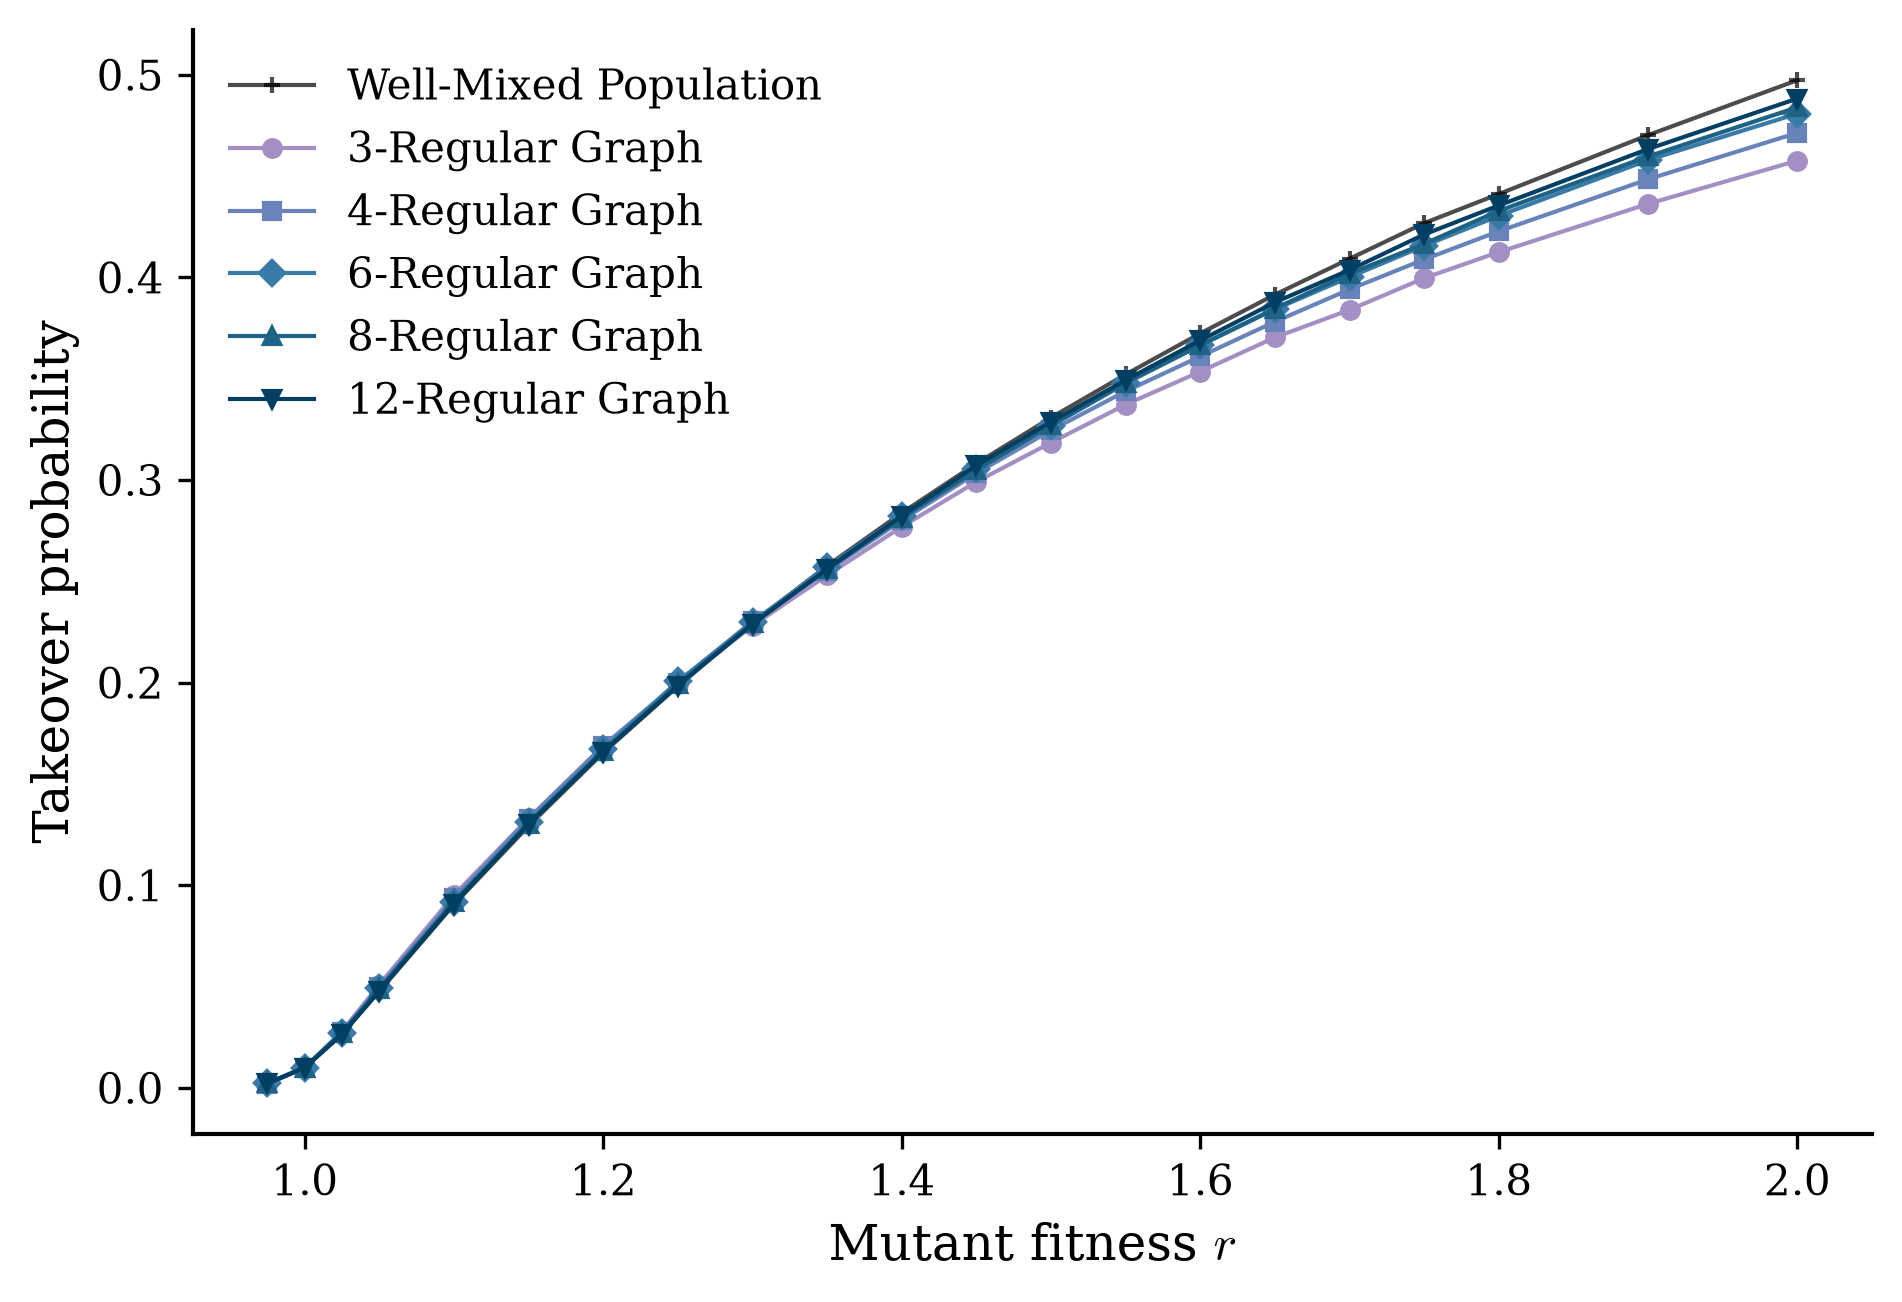

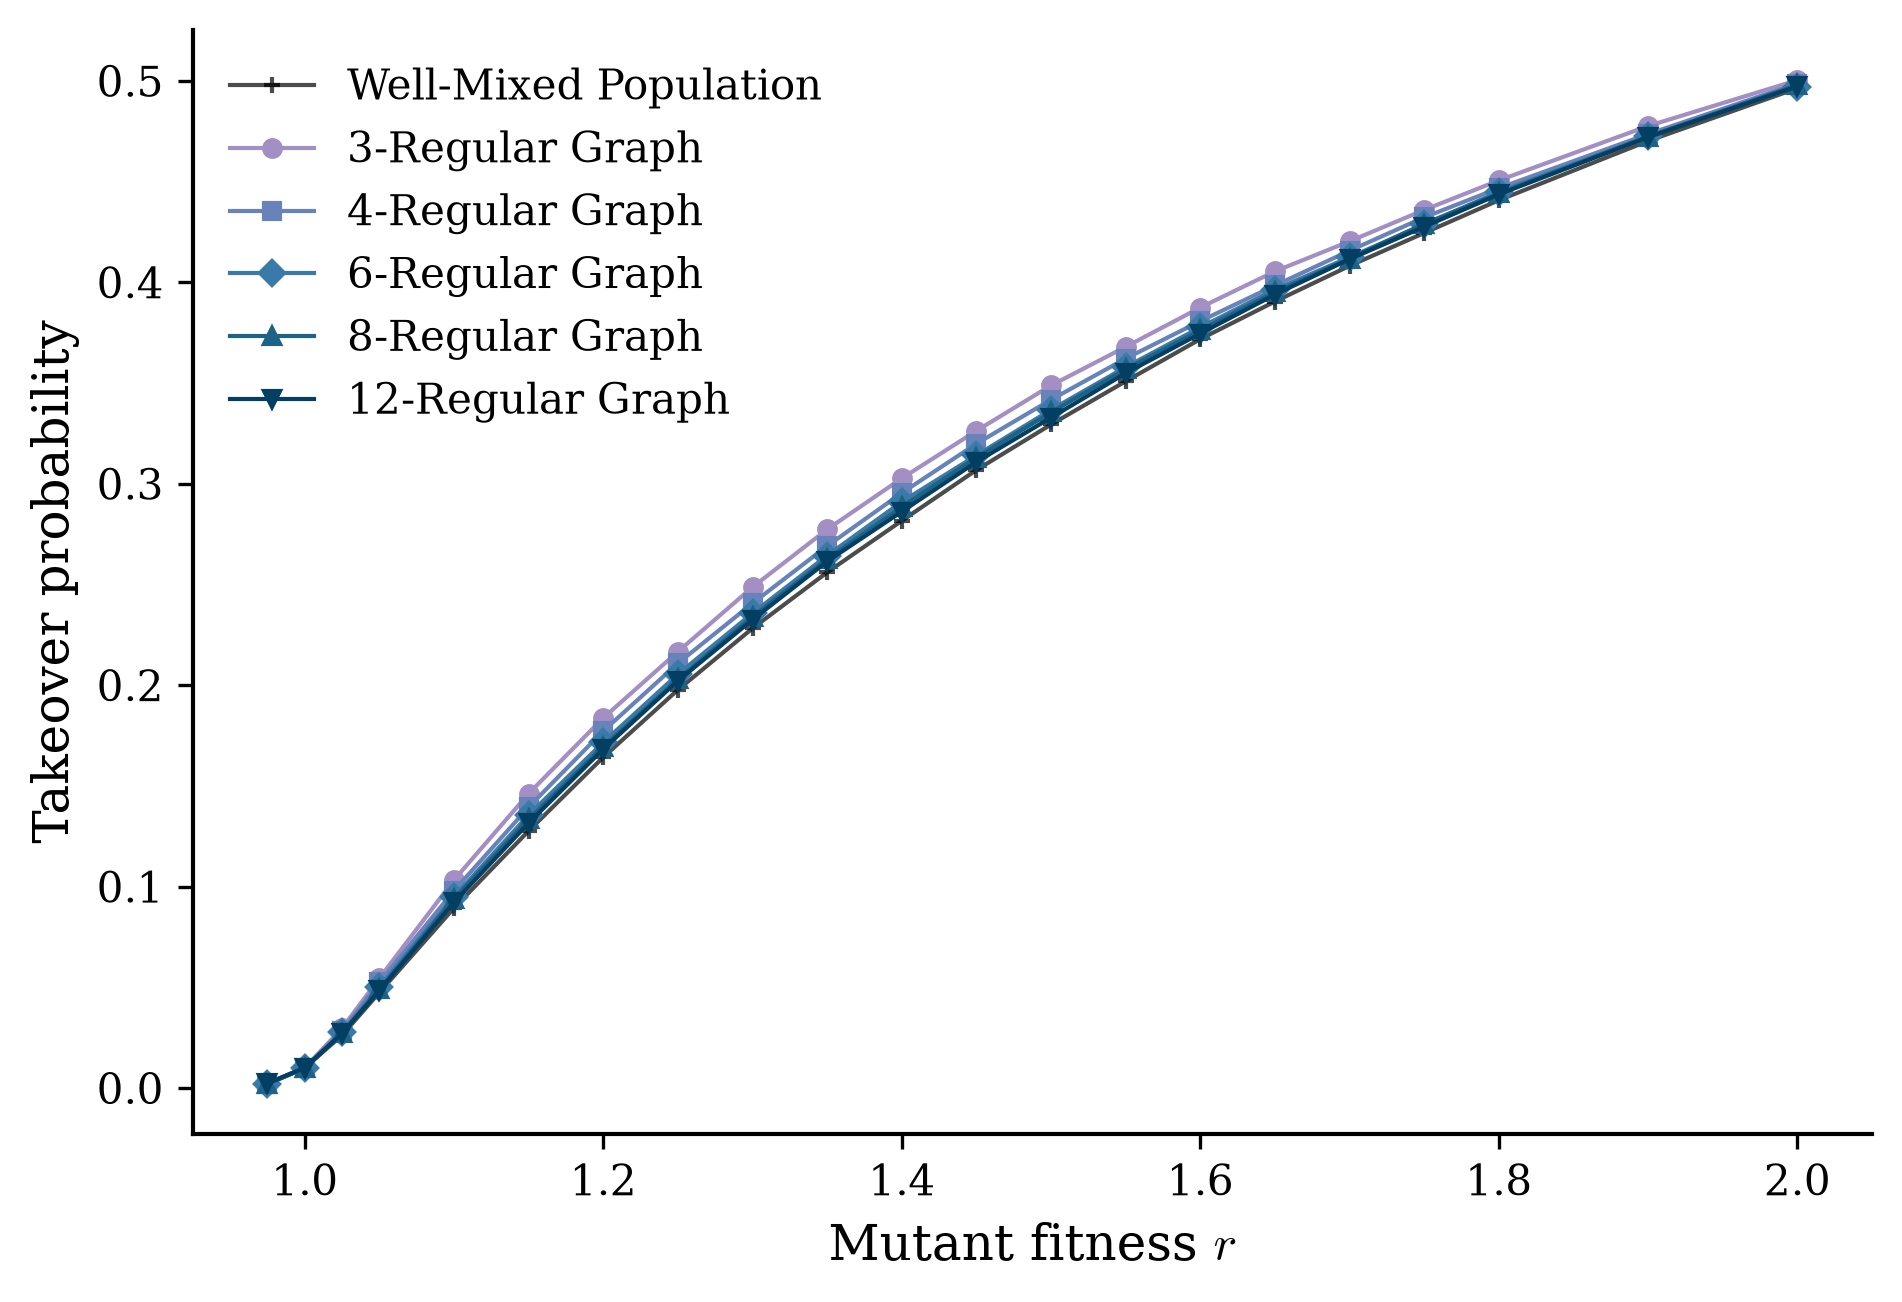

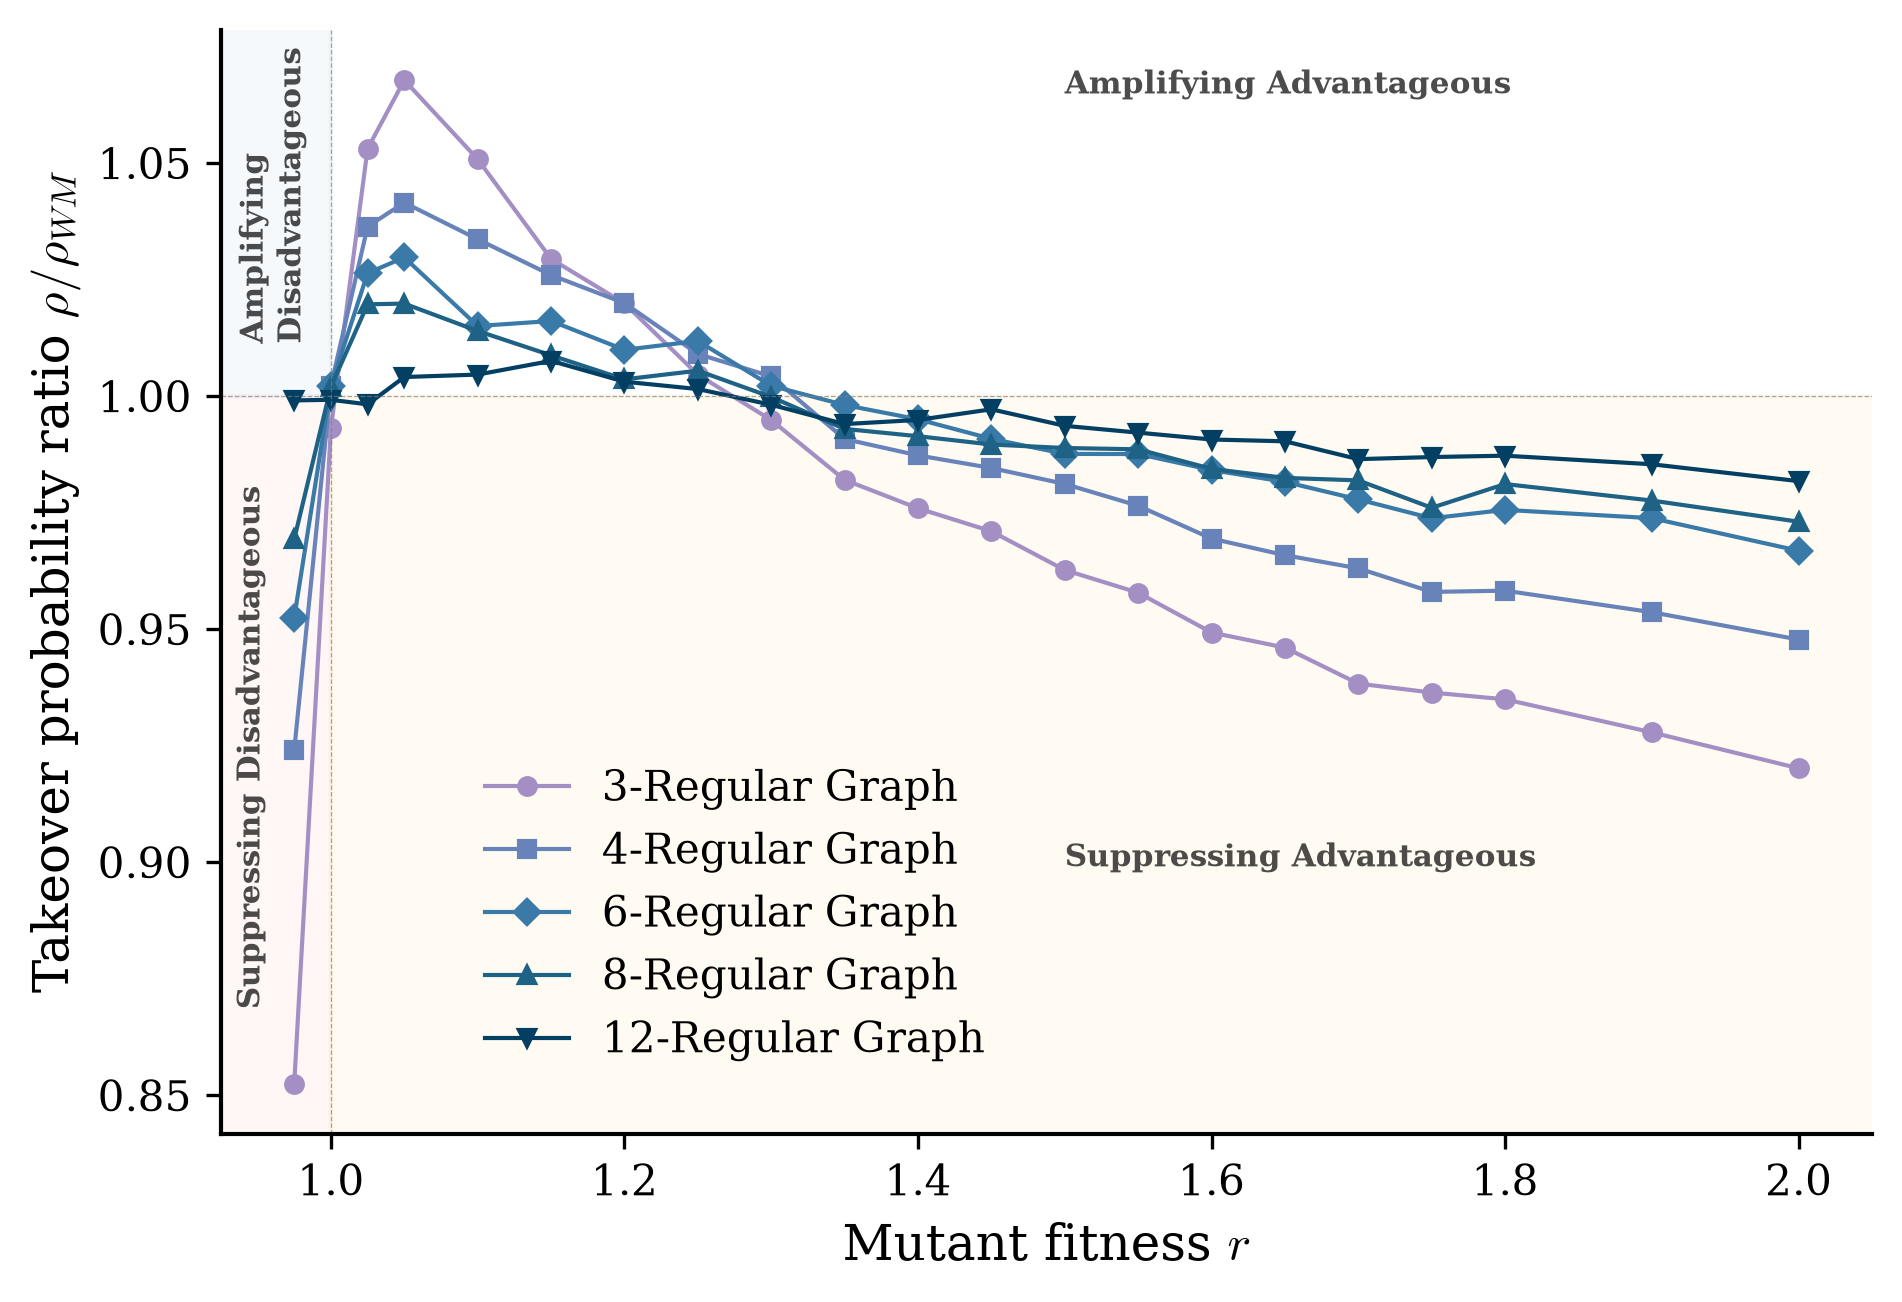

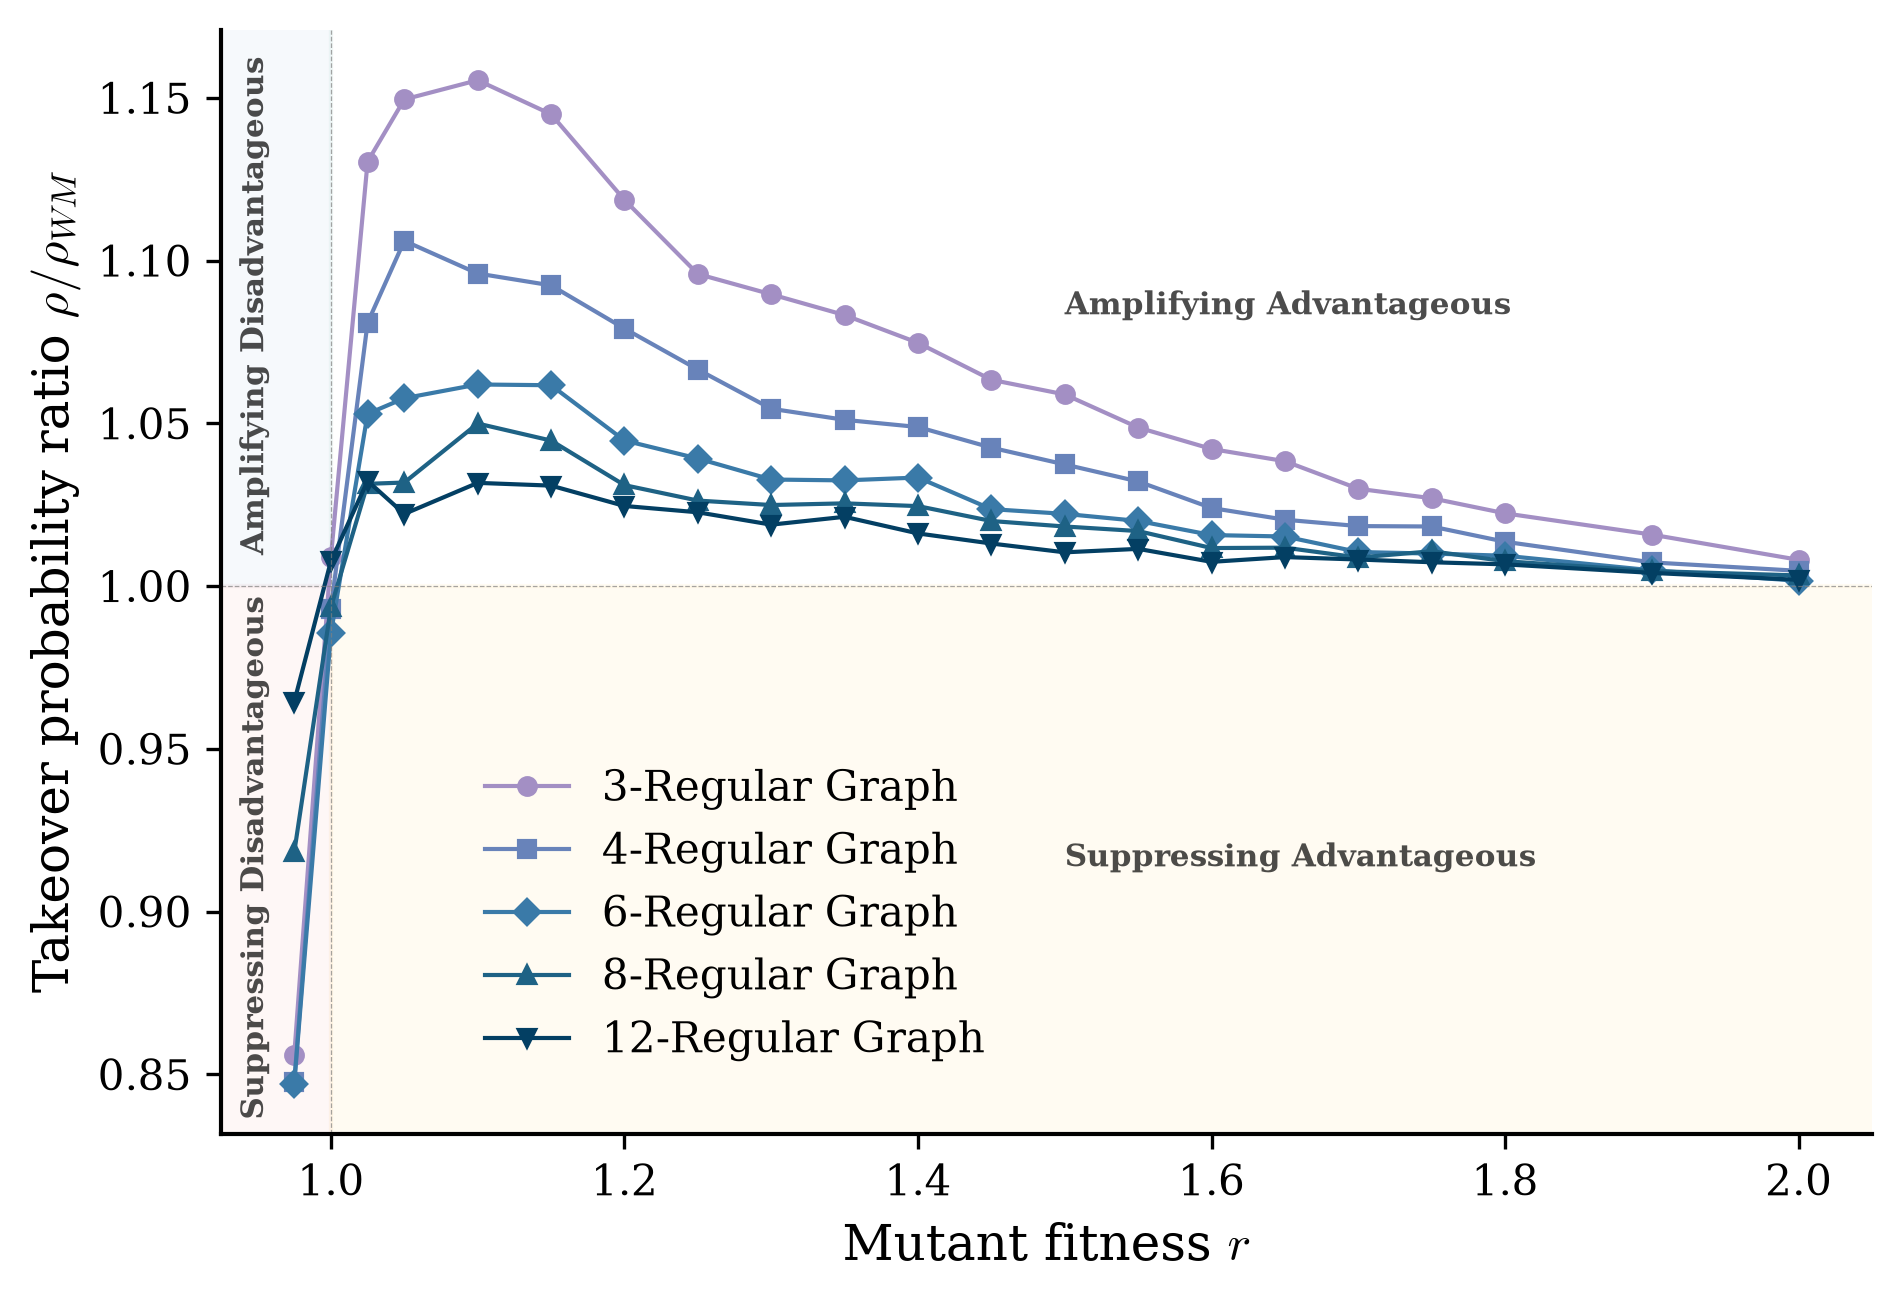

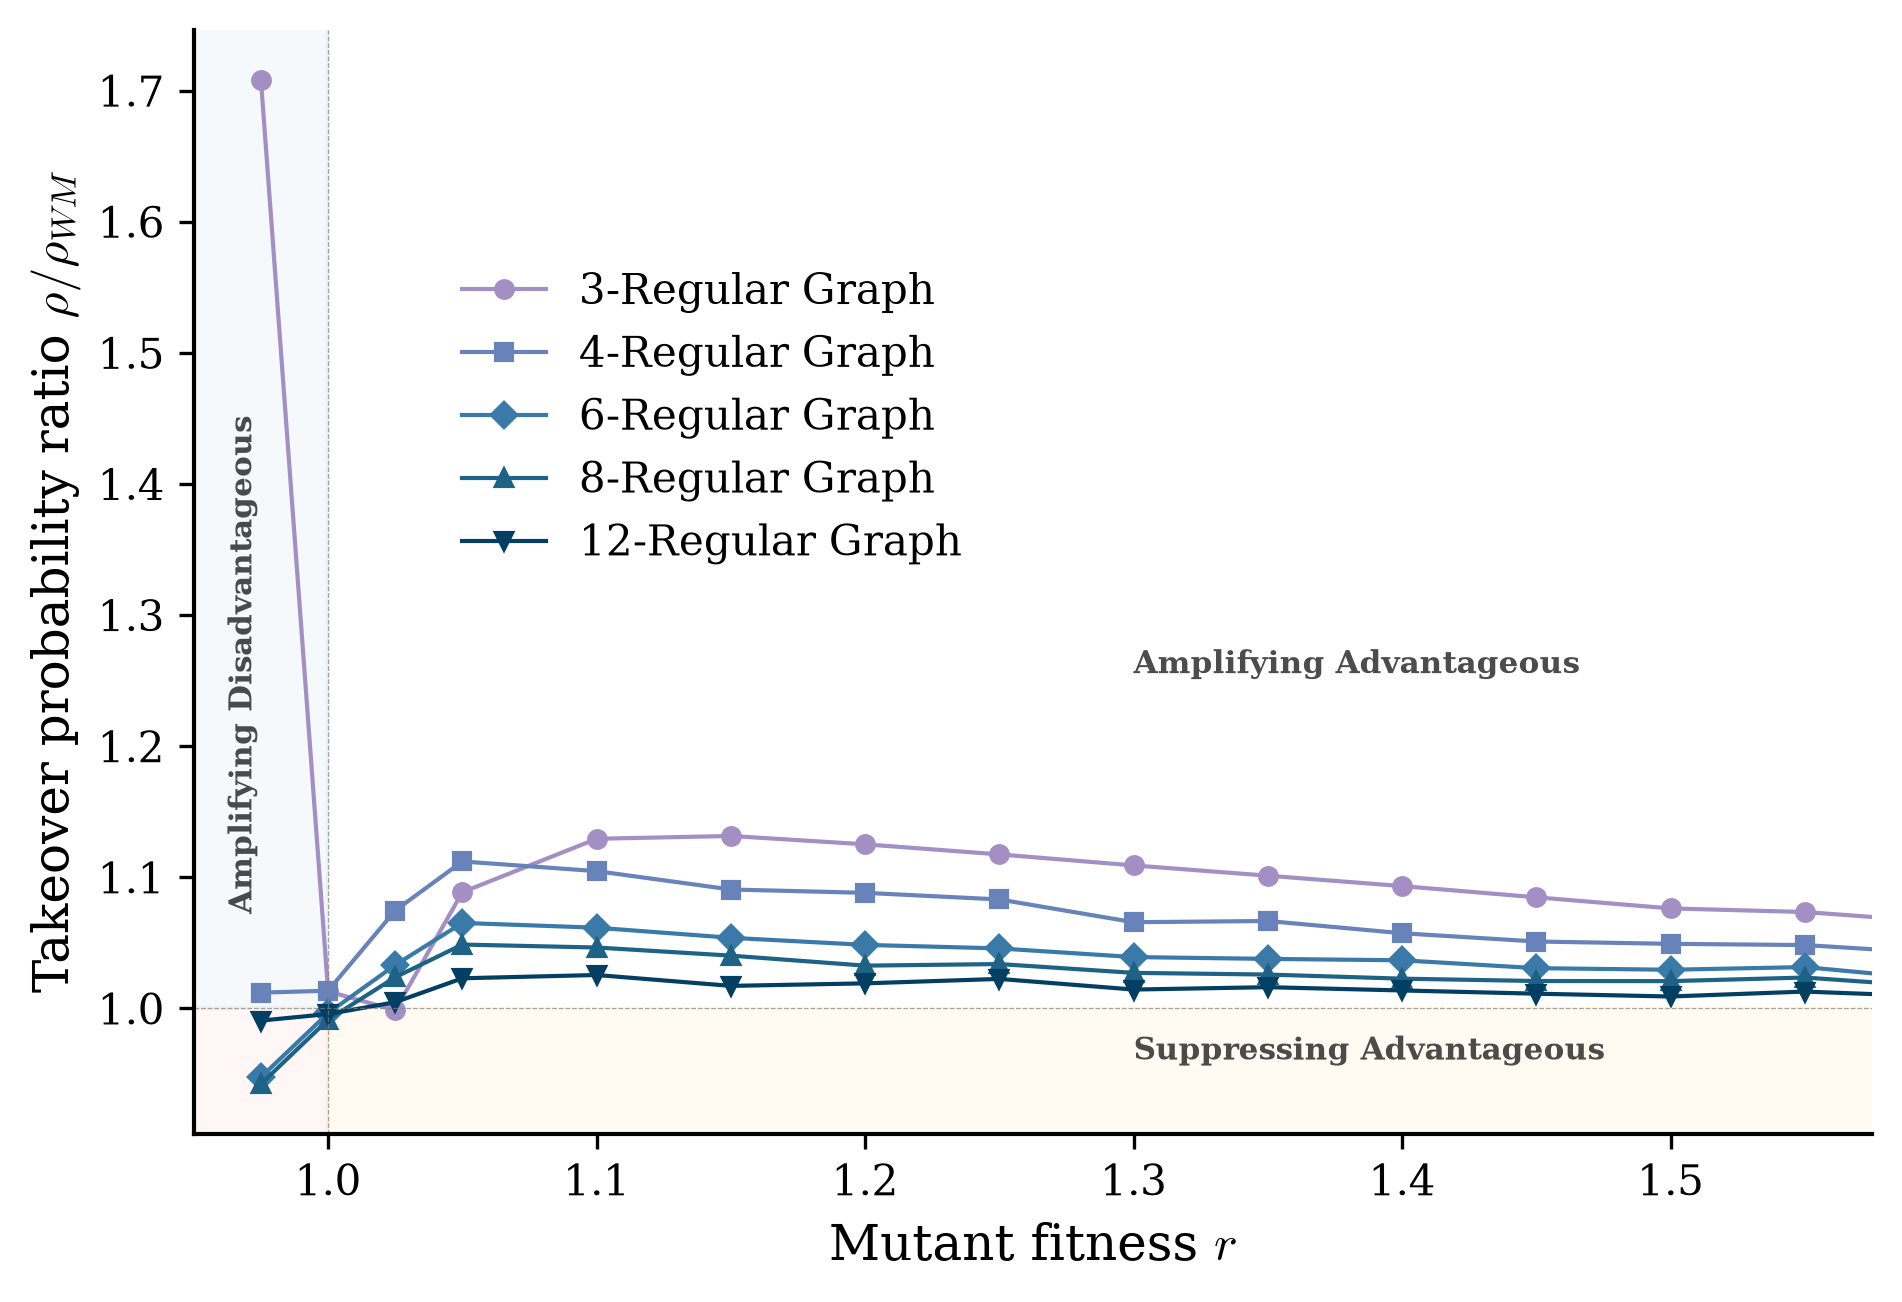

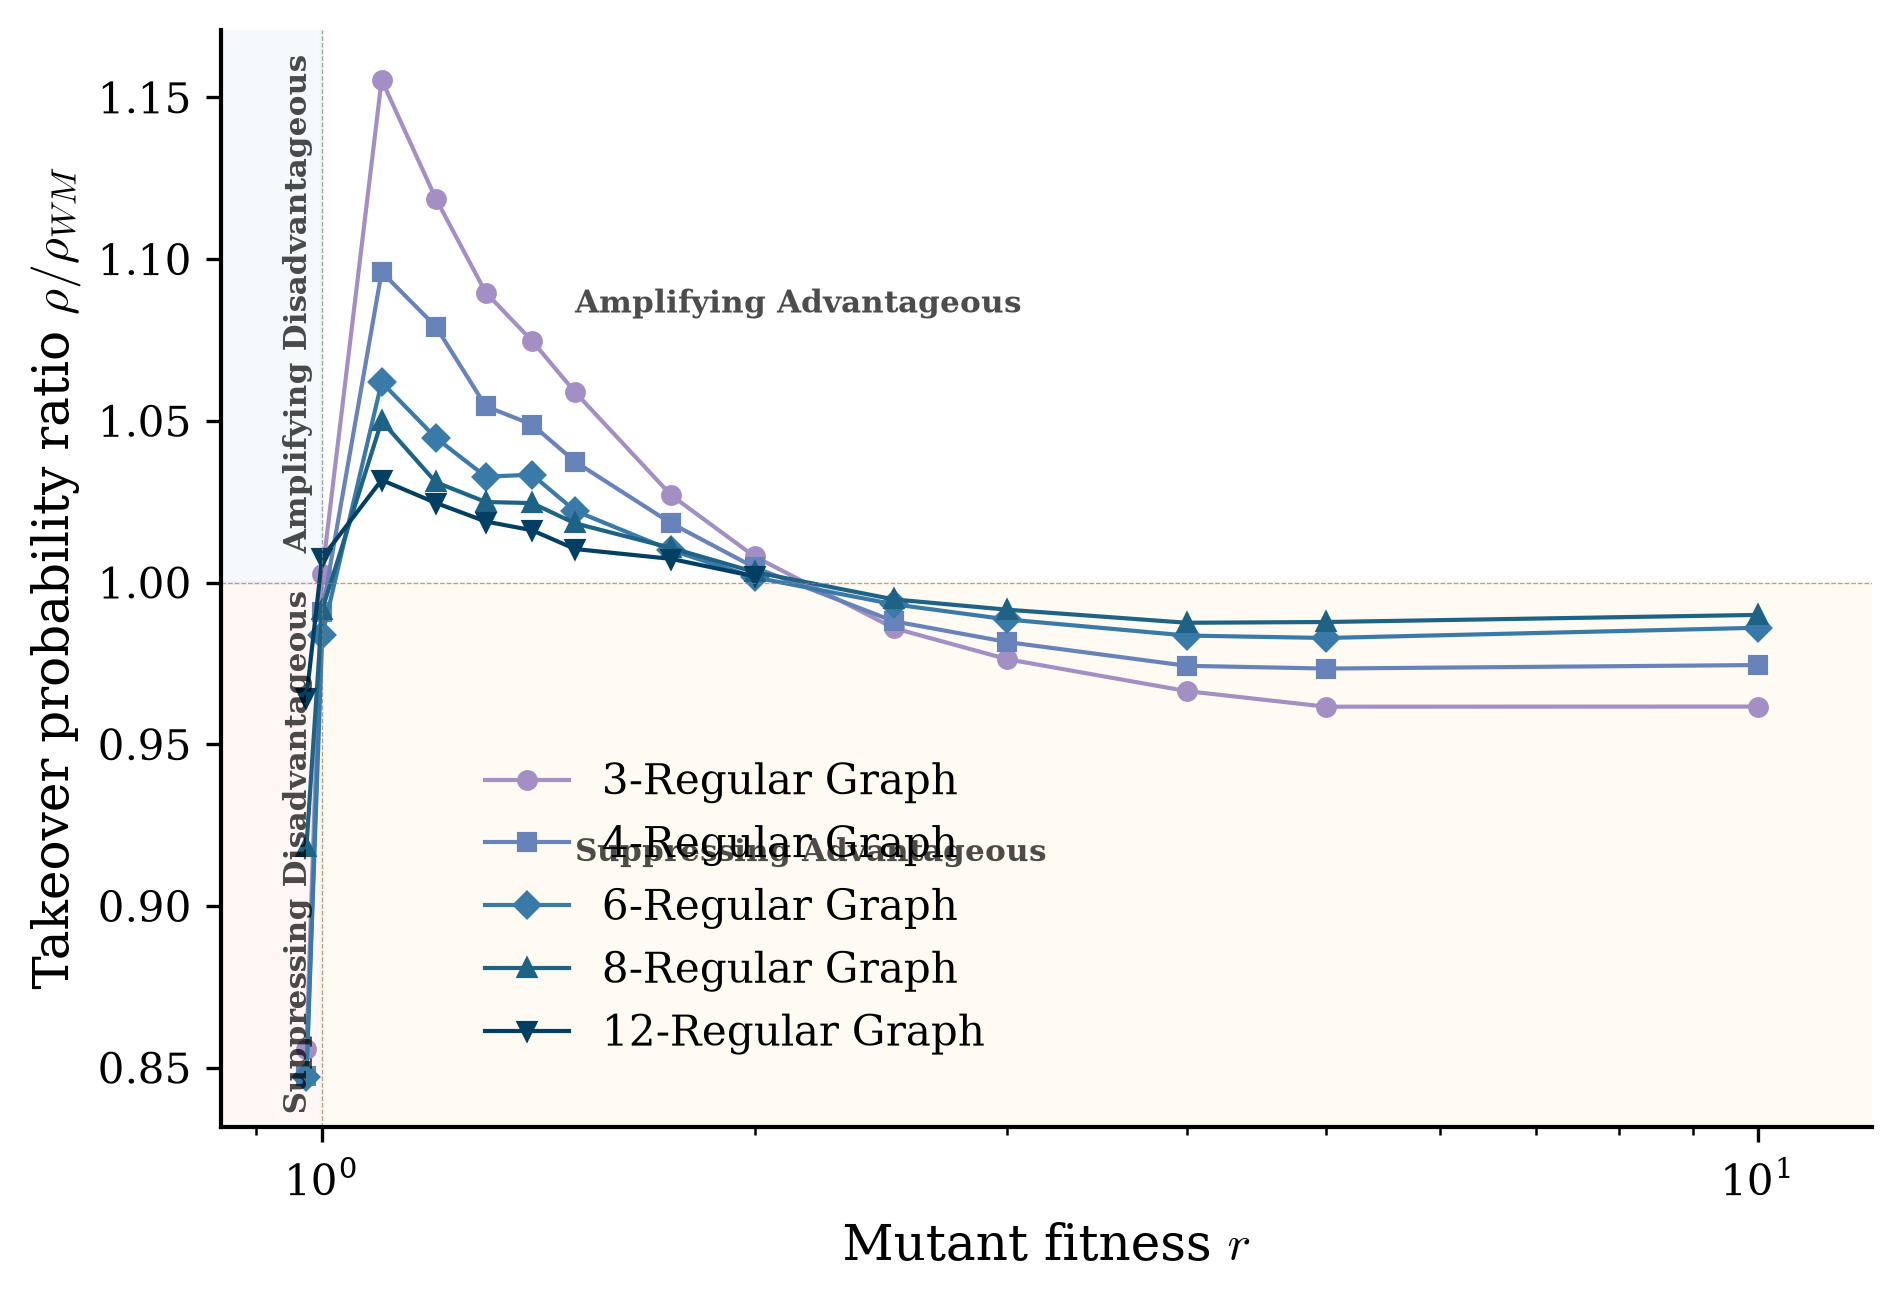

In [95]:
def plot_regular_figures(comparison, extended, deathrates):

    for graph in graphs:
        print(graph['name'])

        if graph['code'] == 'r':

            for d_id, d in enumerate(deathrates):

                fig = plt.figure(figsize=(6.5, 4.5))
                suffix = "_comparison" if comparison else ""
                if extended and comparison and d == 0.5:
                    suffix += "_extended"

                if comparison:
                    M_temp_rs, M_means, M_cis, M_ns = get_well_mixed_data(d, adjusted_M=adjusted_M)
                    plot_regular_graphs(
                        plt, ks, d,
                        adjusted_M=adjusted_M,
                        temp_ks=ks,
                        style='-',
                        comparison_ps=M_means,
                        comparison_rs=[r for r in M_temp_rs if r>=min_r_for_comparison],
                        comparison_ns=M_ns,
                        comparison_cis=M_cis,
                        add_inset=include_inset,
                        inset_bounds=d_configs[d]['inset_bounds'],
                        inset_xlim=d_configs[d]['inset_xlim'],
                        inset_ylim=d_configs[d]['inset_ylim'],
                        connecting_lines=d_configs[d]['connecting_lines'],
                        hline=True,
                        errorbars=errorbars,
                        inset_errorbars=inset_errorbars,
                        top_left = d_configs[d]['top_left'],
                        top_right = d_configs[d]['top_right'],
                        bottom_left = d_configs[d]['bottom_left'],
                        bottom_right = d_configs[d]['bottom_right'],
                        background=comparison,
                        rotate_ylabel = not difference_not_ratio,
                        top_left_split= d_configs[d]['top_left_split'],
                        top_right_split= d_configs[d]['top_right_split'],
                        bottom_left_split= d_configs[d]['bottom_left_split'],
                        bottom_right_split= d_configs[d]['bottom_right_split']
                    )
                    plt.ylabel(r"Takeover probability ratio $\rho / \rho_{WM}$")
                else:
                    plot_well_mixed_graph(plt, d)
                    plot_regular_graphs(plt, ks, d, adjusted_M=adjusted_M,temp_ks=ks,background=False,add_inset=include_inset, 
                                        inset_bounds=d_configs_no_comp[d]['inset_bounds'],
                                        inset_xlim=d_configs_no_comp[d]['inset_xlim'],
                                        inset_ylim=d_configs_no_comp[d]['inset_ylim'],
                                        connecting_lines=d_configs_no_comp[d]['connecting_lines'],
                                        )

                    plt.ylabel(r"Takeover probability")
                plt.xlabel(r"Mutant fitness $r$")

                if title:
                    plt.title(rf"Regular graphs ($d={d}$)")

                if extended:
                    d_configs[0.5]['xlim'] = (0.85, 12)
                if 'xlim' in d_configs[d]:
                    xlim = d_configs[d]['xlim']
                if 'ylim' in d_configs[d]:
                    ylim = d_configs[d]['ylim']
                if xlim is not None:
                    plt.xlim(xlim)
                if ylim is not None:
                    plt.ylim(ylim)
                if log_plot:
                    plt.xscale('log')
                    plt.yscale('log')
                if extended:
                    plt.xscale('log')
                if legend:
                    plt.legend(frameon=False,fontsize=legend_fontsize,loc=d_configs[d]['legend_loc'] if ('legend_loc' in d_configs[d] and comparison) else 'best')
                plt.tight_layout()
                if save_fig:
                    plt.savefig(f"regular_graphs_d{d}{suffix}.pdf", format="pdf")
plot_regular_figures(False, False, [0.2, 0.5])
plot_regular_figures(True, False, [0.2, 0.5, 0.6])
rs = extended_rs
plot_regular_figures(True, True, [0.5])
rs = standard_rs
comparison = True


In [96]:
d_configs = {
    0.2: {
        'inset_bounds': [0.125, 0.325, 0.3, 0.3],
        'inset_xlim': (0.96, 1.04),
        'inset_ylim': (-0.001, 0.0005),
        'connecting_lines': (1,2),
        'top_left' : (0.9125, 0.725),
        'top_right' : (1.15, 0.8),
        'bottom_left' : (0.9175, 0.275),
        'bottom_right' : (1.15, 0.08),
        'legend_loc': (0.15, 0.05),
        'xlim':(0.9,2.05),
        'ylim':None,
        'top_left_split': True,
        'top_right_split':False,
        'bottom_left_split':False,
        'bottom_right_split':False
    },
    0.5: {
        'inset_bounds': [0.125, 0.38, 0.3, 0.3],
        'inset_xlim': (0.96, 1.04),
        'inset_ylim': (-0.0005, 0.001),
        'connecting_lines': (1,2),
        'top_left' : (0.9175, 0.65),
        'top_right' : (1.15, 0.8),
        'bottom_left' : (0.9125, 0.2),
        'bottom_right' : (1.15, 0.08),
        'xlim':(0.9,2.05),
        'ylim':None,
        'top_left_split': False,
        'top_right_split':False,
        'bottom_left_split':True,
        'bottom_right_split':False
    }
}        


In [97]:
comparison_deathrates = [0.2, 0.5]


f3 0.2 1 Neutral prob: 0.009990604079922744
Missing File [Errno 2] No such file or directory: '/Users/george/project-data/EvoLudoWrapperProject/EvoLudoWrapper/constantFitness/fixationProbabilities/EcoMoran_graphs/varyingRconstantK/results/eMoran-N-187-geom-lower_f3-d-0.2-r-1-tr-10.txt'
f4 0.2 [0.010065958197686159, 0.010067704304678533, 0.010066441027391038, 0.010067247096482613, 0.010065845121914295, 0.010065510165047996, 0.010066217389909957, 0.010066938902197495, 0.010065806518670657, 0.010065325674734392, 0.010066084448368607, 0.010066371614603728, 0.010065986467026078, 0.010066871104013922, 0.010064515962805413, 0.010066877893925389, 0.010066627281322982, 0.010066425118098294, 0.010065970356522578, 0.010066944374736448] [0.975, 1, 1.025, 1.05, 1.1, 1.15, 1.2, 1.25, 1.3, 1.35, 1.4, 1.45, 1.5, 1.55, 1.6, 1.65, 1.7, 1.75, 1.8, 1.9, 2]
f4 0.2 1 Neutral prob: 0.010066283451006828
Missing File [Errno 2] No such file or directory: '/Users/george/project-data/EvoLudoWrapperProject/EvoLudo

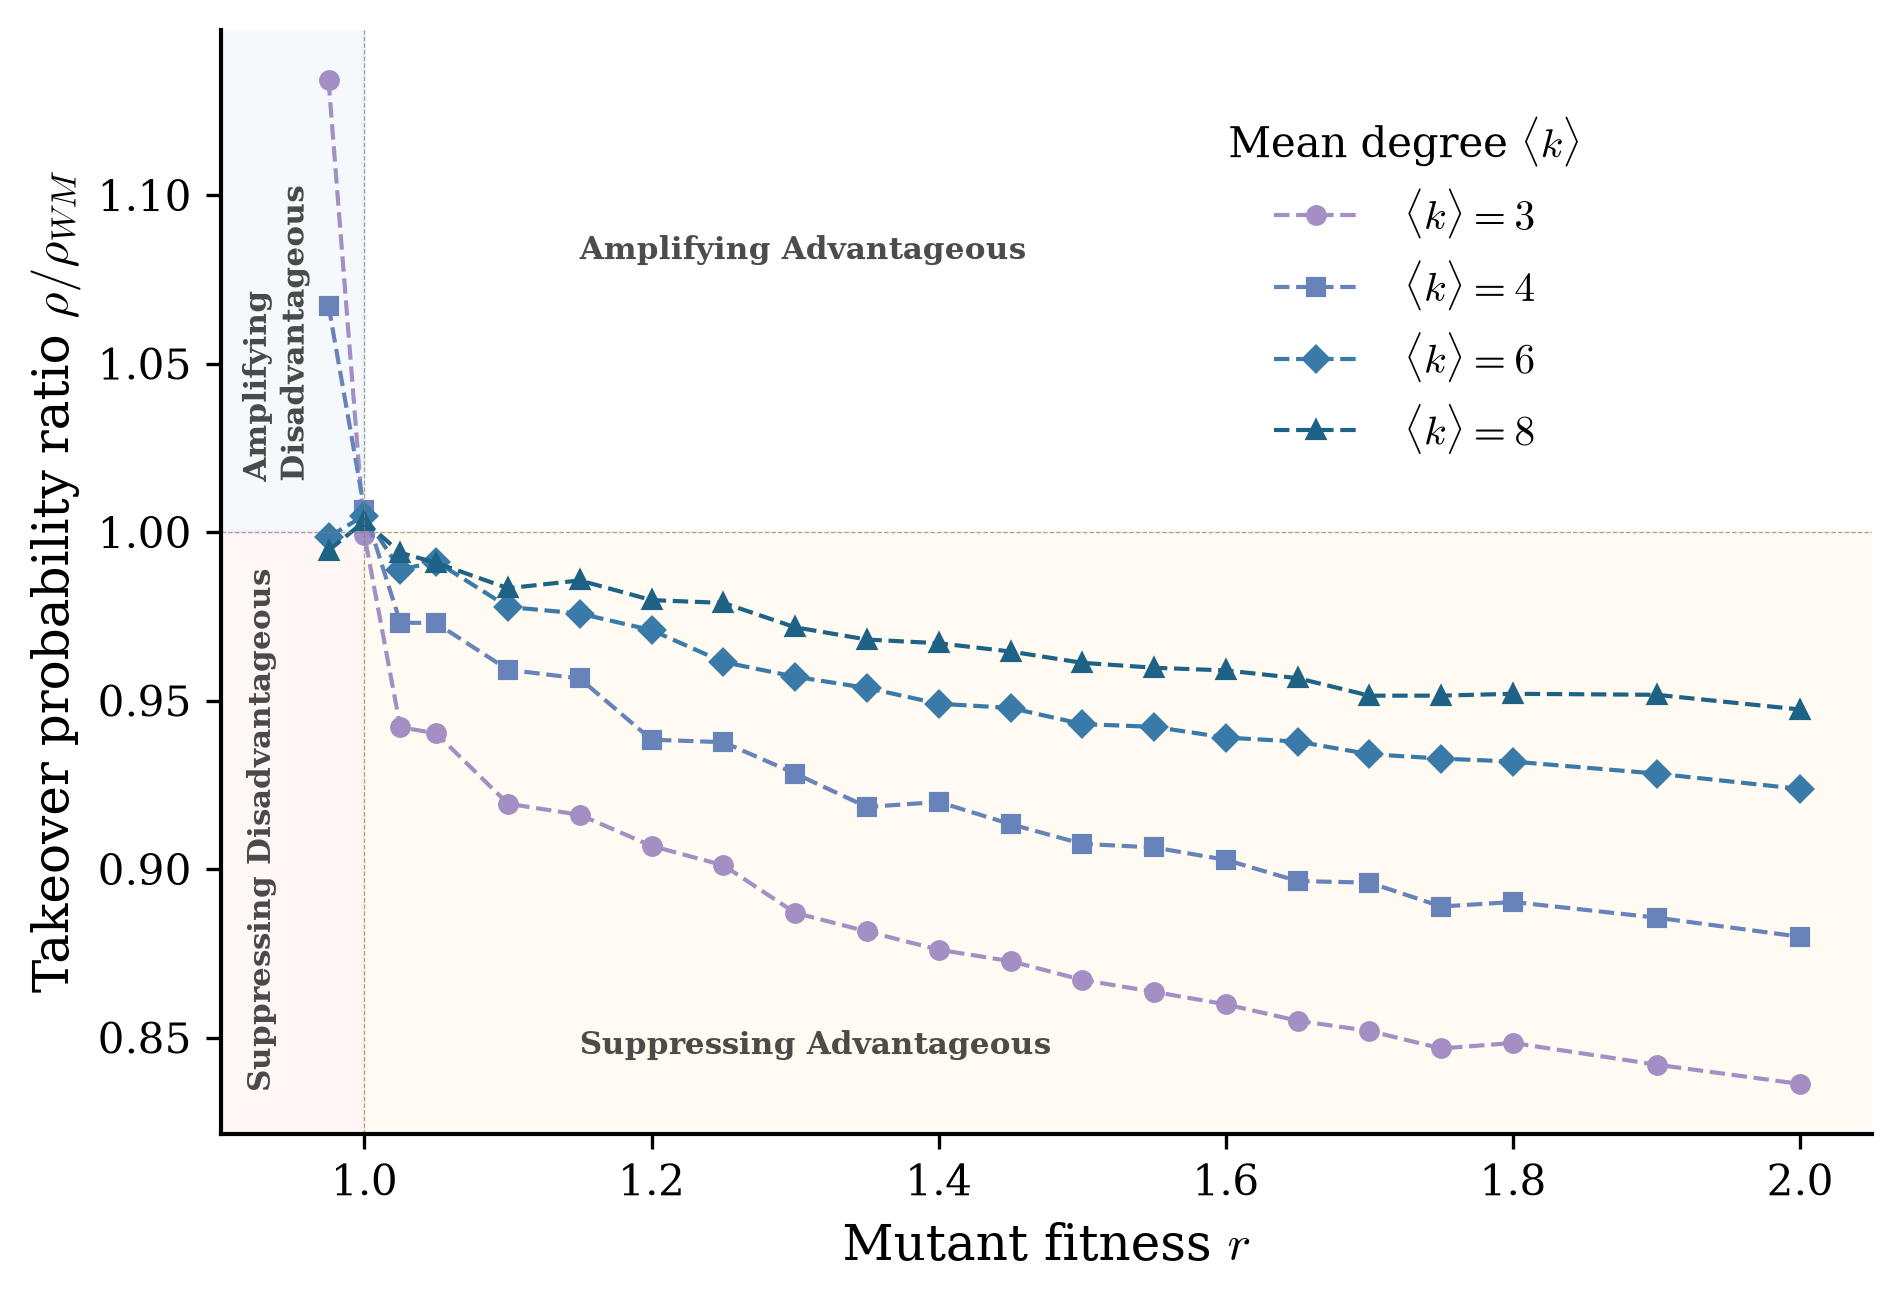

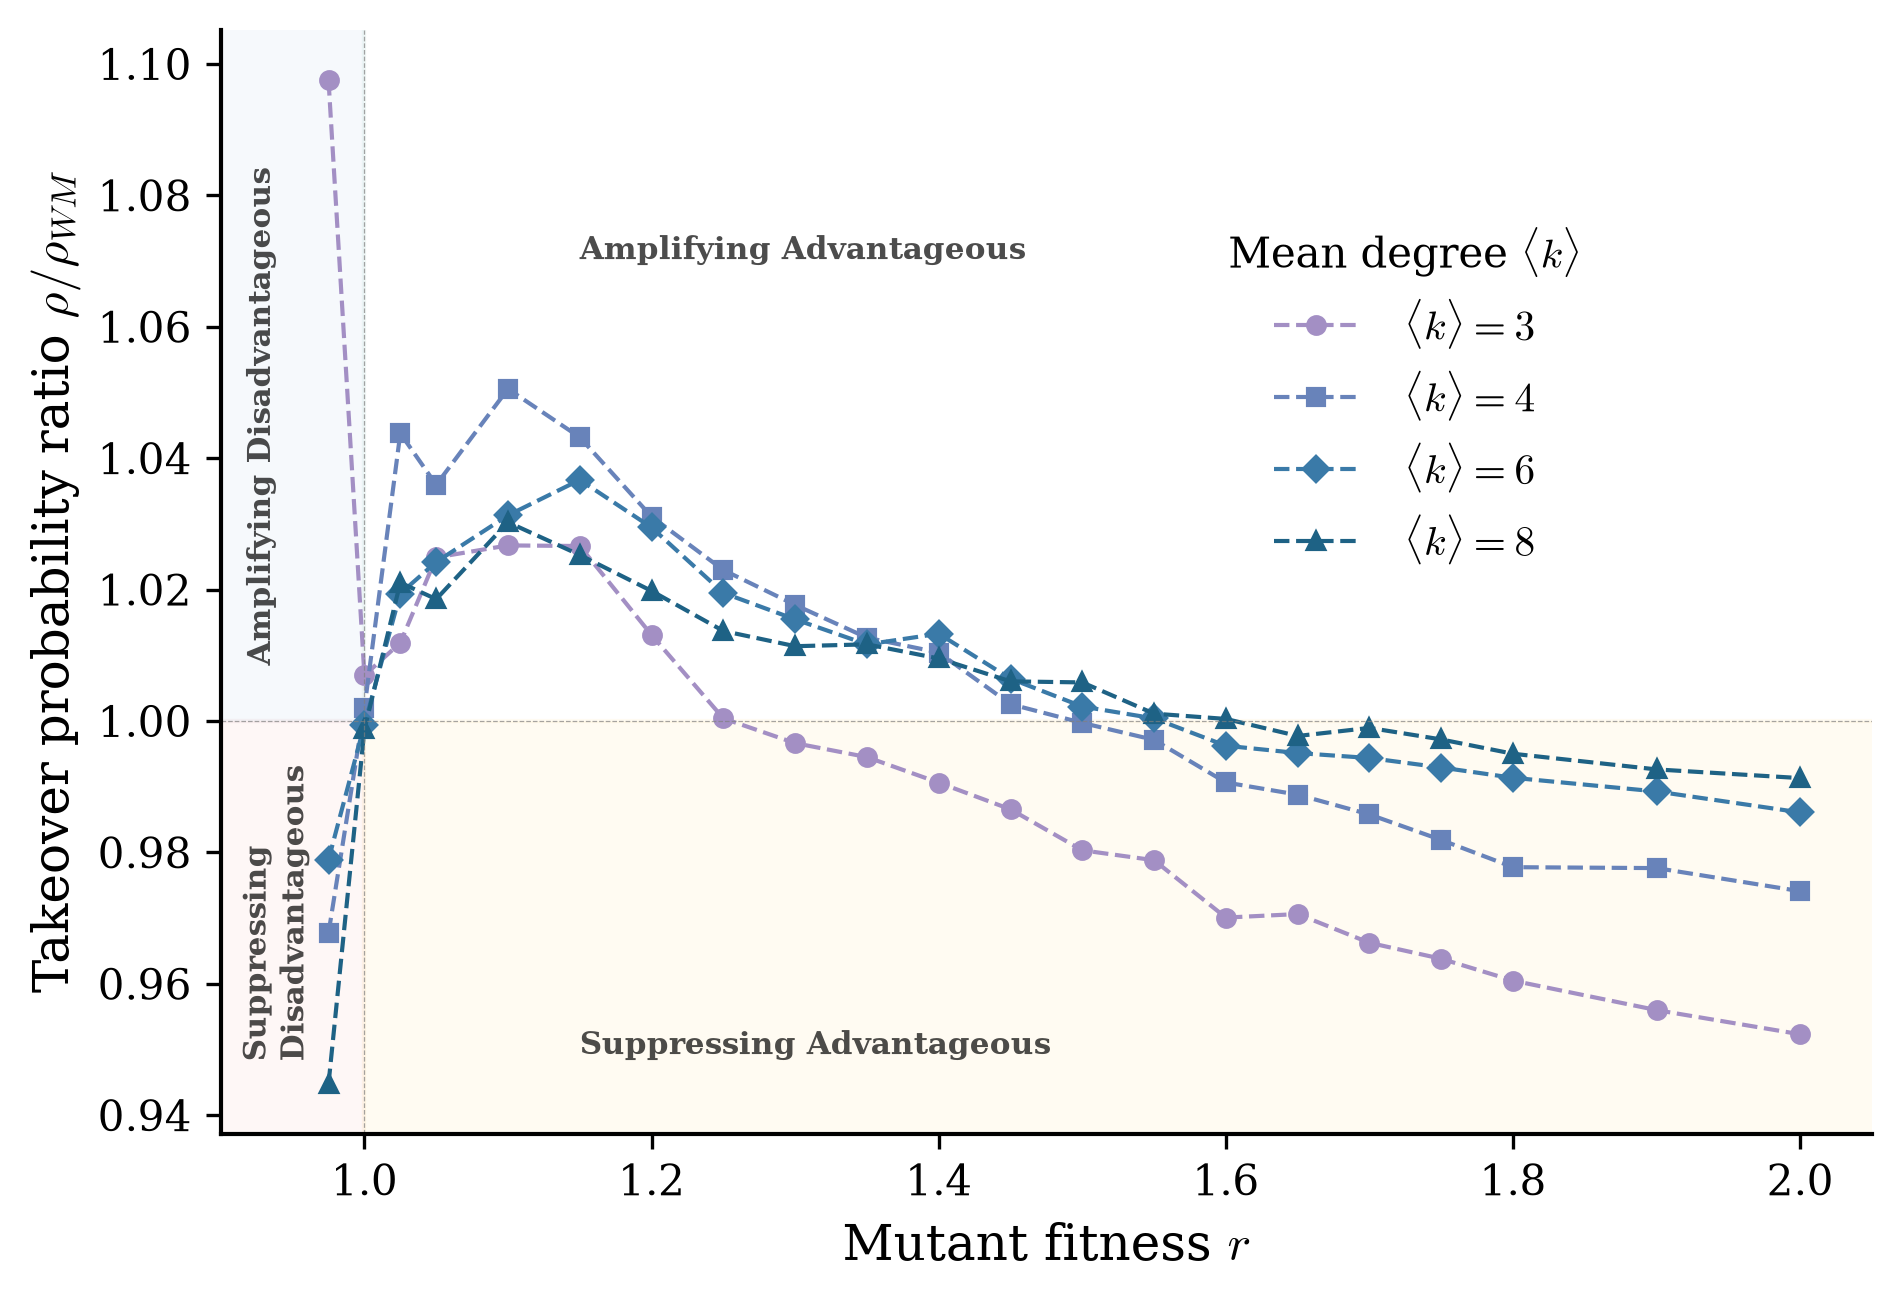

In [98]:
ax = None
ax_inset = None
for graph in graphs:
    if graph['code'] == 'f' or graph['code'] == 'F':

        for d in comparison_deathrates:

            fig = plt.figure(figsize=(6.5, 4.5))
            suffix = "_comparison" if comparison else ""

            if comparison:
                M_temp_rs, M_means, M_cis, M_ns = get_well_mixed_data(d, adjusted_M=adjusted_M)

                plot_scale_free_graphs(
                    plt, fs, d,
                    adjusted_M=adjusted_M,
                    comparison_ps=M_means,
                    comparison_rs=[r for r in M_temp_rs if r>=min_r_for_comparison],
                    comparison_cis=M_cis,
                    comparison_ns=M_ns,
                    style='--',
                    upper=(graph['code']=='F'),
                    add_inset=include_inset,
                    inset_bounds=d_configs[d]['inset_bounds'],
                    inset_xlim=d_configs[d]['inset_xlim'],
                    inset_ylim=d_configs[d]['inset_ylim'],
                    connecting_lines=d_configs[d]['connecting_lines'],
                    hline=True,
                    ax=ax,
                    ax_inset=ax_inset,
                    alpha=1,
                    background=True,
                    errorbars=errorbars,
                    point_styles = [point_styles[i] for i in range(len(ks)) if ks[i] in fs],
                    top_left = d_configs[d]['top_left'],
                    top_right = d_configs[d]['top_right'],
                    bottom_left = d_configs[d]['bottom_left'],
                    bottom_right = d_configs[d]['bottom_right'],
                    top_left_split= d_configs[d]['top_left_split'],
                    top_right_split= d_configs[d]['top_right_split'],
                    bottom_left_split= d_configs[d]['bottom_left_split'],
                    bottom_right_split= d_configs[d]['bottom_right_split'],
                    rotate_ylabel=True
                )


                plt.ylabel(r"Takeover probability ratio $\rho / \rho_{WM}$")

                if title:
                    plt.title(rf"Scale-free graphs ($d={d}$)")
            plt.xlabel(r"Mutant fitness $r$")

            if log_plot:
                plt.xscale('log')
                plt.yscale('log')
            if 'xlim' in d_configs[d]:
                xlim = d_configs[d]['xlim']
            if 'ylim' in d_configs[d]:
                ylim = d_configs[d]['ylim']
            if xlim is not None:
                plt.xlim(xlim)
            if ylim is not None:
                plt.ylim(ylim)
            if legend:
                if d == 0.2:
                    plt.legend(frameon=False,fontsize=legend_fontsize,title=r'Mean degree $\langle k \rangle$',title_fontsize=legend_fontsize, loc=(0.6,0.6))
                elif d==0.5:
                    plt.legend(frameon=False,fontsize=legend_fontsize,title=r'Mean degree $\langle k \rangle$',title_fontsize=legend_fontsize, loc=(0.6,0.5))
            plt.tight_layout()
            if save_fig:
                plt.savefig(f"scale_free_graphs_d{d}{suffix}.pdf", format="pdf")


In [99]:
d_configs = {
    0.2: {
        'inset_bounds': [0.125, 0.435, 0.25, 0.25],
        'inset_xlim': (0.96, 1.04),
        'inset_ylim': (-0.001, 0.001),
        'connecting_lines': (1,2),
        'top_left' : (0.935, 0.85),
        'top_right' : (1.5, 0.85),
        'bottom_left' : (0.935, 0.35),
        'bottom_right' : (1.5, 0.3125),
        'legend_loc': (0.15, 0.05),
        'xlim':(0.925,2.05),
        'ylim':None,
        'top_left_split': True,
        'top_right_split':False,
        'bottom_left_split':False,
        'bottom_right_split':False
    },
    0.5: {
        'inset_bounds': [0.335, 0.155, 0.225, 0.225],
        'inset_xlim': (0.96, 1.04),
        'inset_ylim': (-0.001, 0.002),
        'connecting_lines': (2,3),
        'top_left' : (0.935, 0.75),
        'top_right' : (1.5, 0.75),
        'bottom_left' : (0.9375, 0.25),
        'bottom_right' : (1.5, 0.35),
        'legend_loc': (0.15, 0.05),
        'xlim':(0.925,2.05),
        'ylim':None,
        'top_left_split': True,
        'top_right_split':False,
        'bottom_left_split':False,
        'bottom_right_split':False
    }
}


Plotting d=0.2
{'code': 'n', 'name': 'von Neumann square lattice', 'pop_size': None, 'comparison_graphs': []}
Well-mixed data for comparison: [0.975, 1, 1.025, 1.05, 1.1, 1.15, 1.2, 1.25, 1.3, 1.35, 1.4, 1.45, 1.5, 1.55, 1.6, 1.65, 1.7, 1.75, 1.8, 1.9, 2] [0.0026586199272137217, 0.01055365531128534, 0.026862939804026556, 0.04742760186383305, 0.0904321208713692, 0.12950714629540175, 0.16592114103370634, 0.19798344282549837, 0.2289452530618464, 0.257228636897486, 0.2844848635679247, 0.30750415995550984, 0.33164376264764384, 0.351737815237432, 0.3726197891571304, 0.3906735146367065, 0.40799088554402546, 0.4252912236075409, 0.4418118743637723, 0.46995733334285467, 0.4957364949263145] [np.float64(0.00010092671046400765), 0, np.float64(0.0003168982543798875), np.float64(0.00041660132864524443), np.float64(0.0005621277006217953), np.float64(0.000658090381506406), np.float64(0.0007291392730569511), np.float64(0.0007810200346327603), np.float64(0.0008235017010922725), np.float64(0.0008567286792

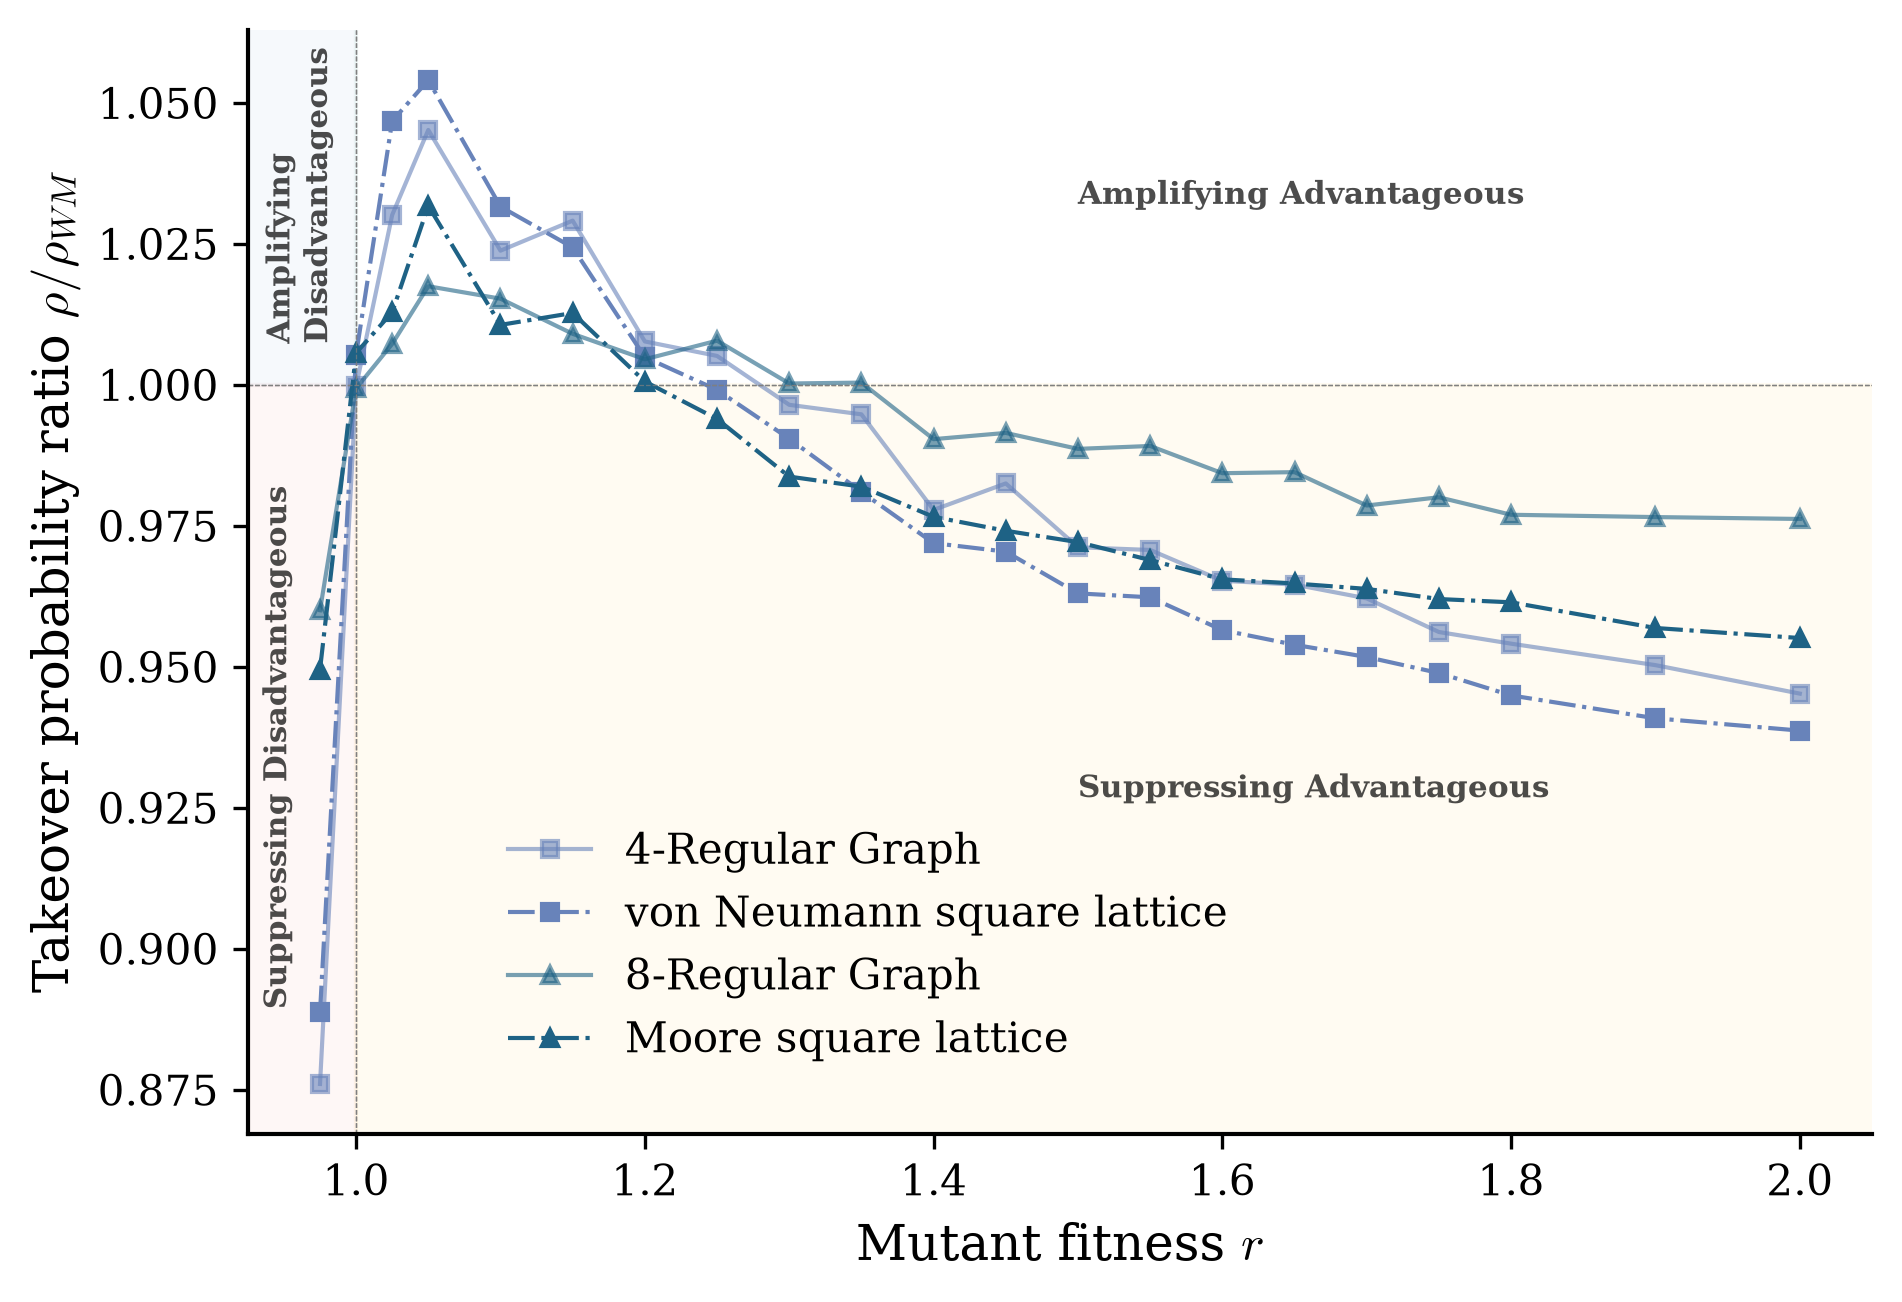

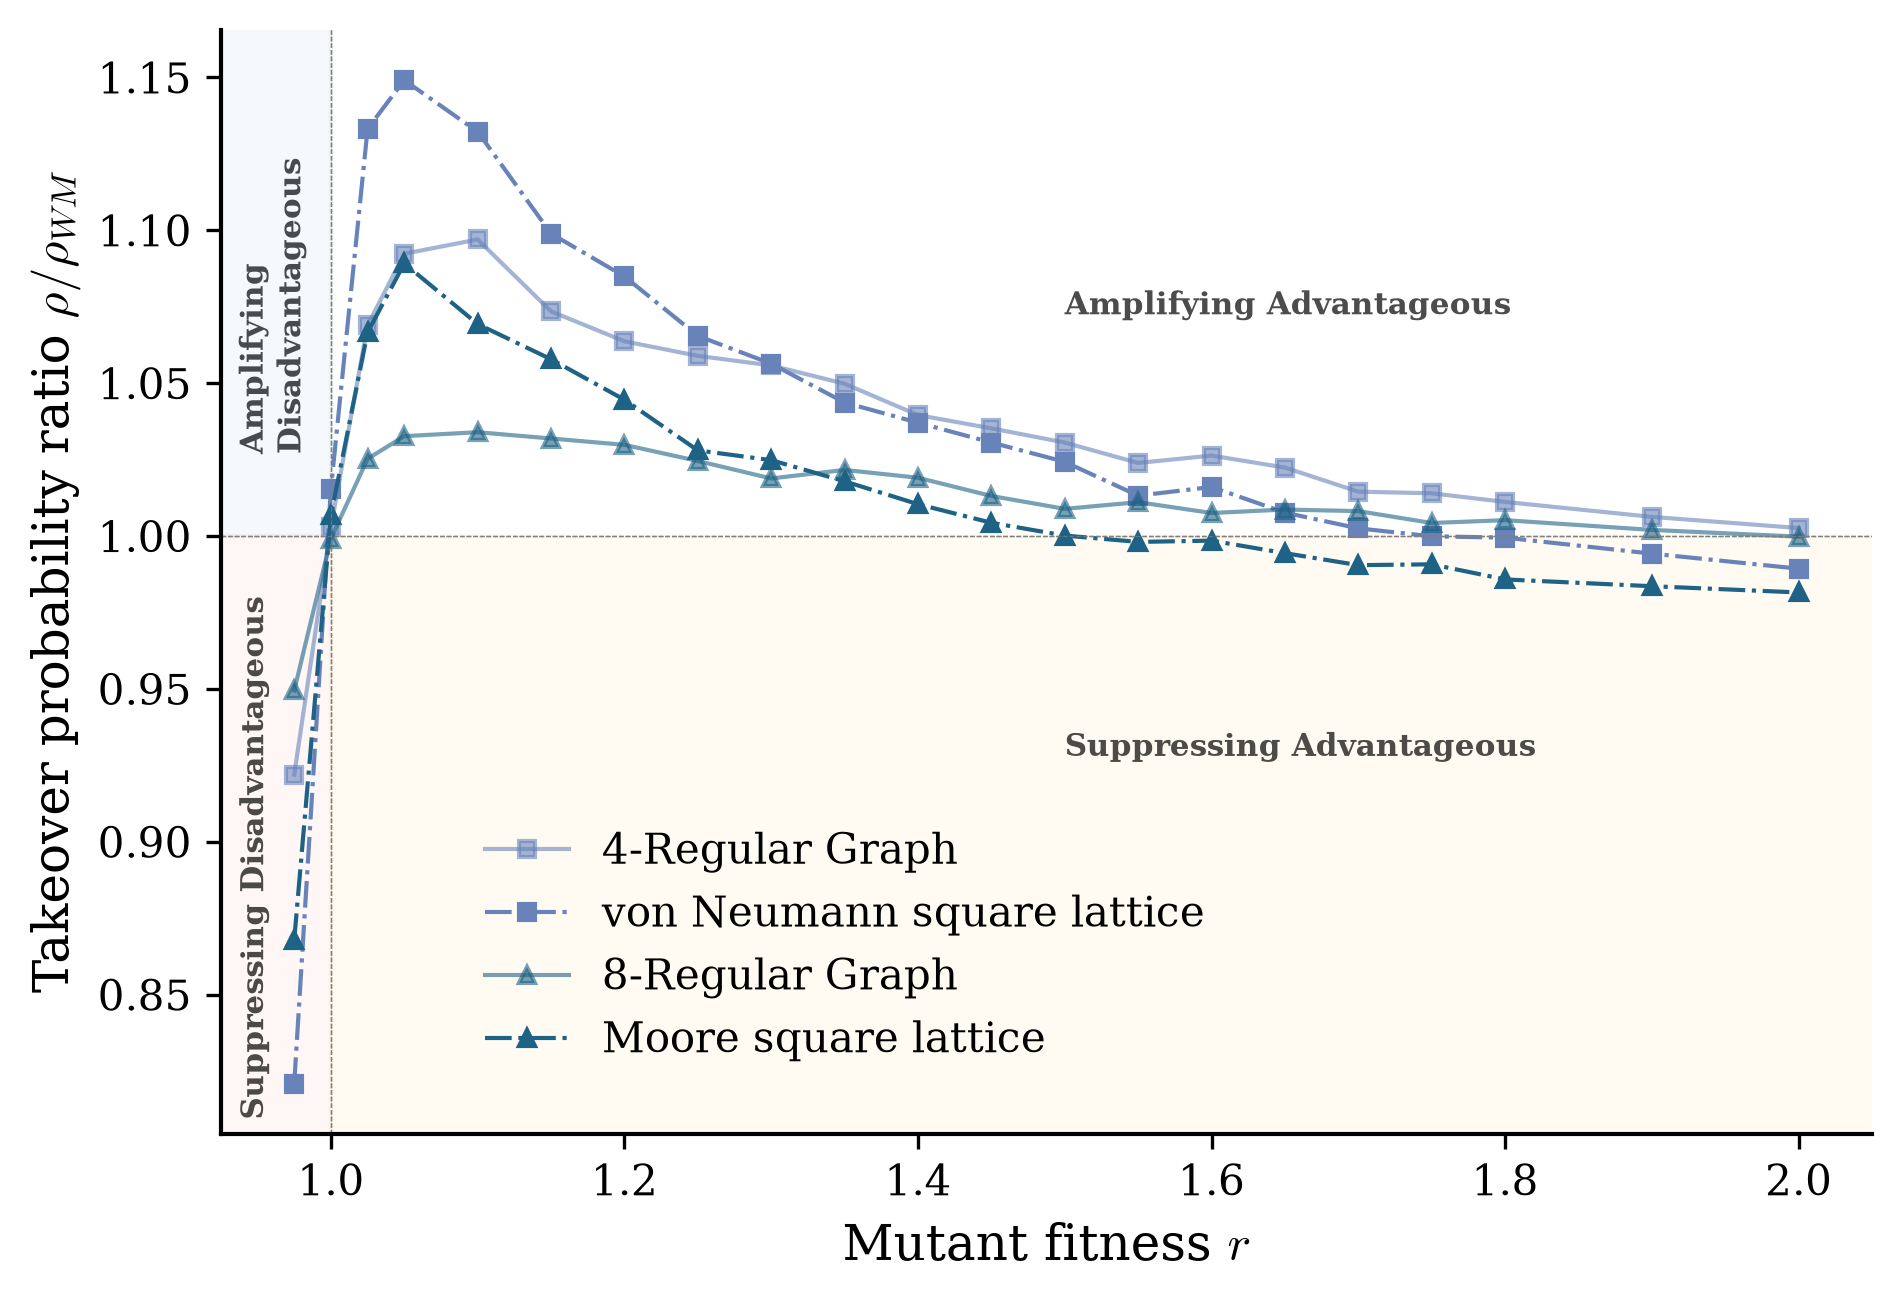

In [100]:

add_inset=False

lattice_graphs = [g for g in graphs if g['code'] in ['n', 'm']]

for d in comparison_deathrates:
    fig = plt.figure(figsize=(6.5, 4.5))
    ax =None
    ax_inset = None
    print(f"Plotting d={d}")
    for graph,col in zip(lattice_graphs,[cols[ks.index(4)],cols[ks.index(8)]]):
        if graph['code'] in ['n', 'm']:
            print(graph)
            suffix = "_comparison" if comparison else ""

            if comparison:
                M_temp_rs, M_means, M_cis, M_ns = get_well_mixed_data(d, adjusted_M=adjusted_M, main_graph=graph['code'])
                print("Well-mixed data for comparison:", M_temp_rs, M_means, M_cis, M_ns)
                if graph['code'] == 'n':
                    temp_k = [4]
                elif graph['code'] == 'm':
                    temp_k = [8]
                ax,ax_inset = plot_regular_graphs(
                    plt, ks, d,
                    adjusted_M=adjusted_M,
                    style='-',
                    comparison_ps=M_means,
                    comparison_rs=[r for r in M_temp_rs if r>=min_r_for_comparison],
                    comparison_ns=M_ns,
                    comparison_cis=M_cis,
                    alpha=regular_alpha*2,
                    temp_ks = temp_k,
                    add_inset=add_inset,
                    inset_bounds=d_configs[d]['inset_bounds'],
                    inset_xlim=d_configs[d]['inset_xlim'],
                    inset_ylim=d_configs[d]['inset_ylim'],
                    connecting_lines=d_configs[d]['connecting_lines'],
                    hline=True,
                    main_graph = graph['code'],
                    ax=ax,
                    ax_inset=ax_inset,
                    background=False,
                    errorbars=errorbars,
                    inset_errorbars=inset_errorbars,
                )
                plot_other_graph(
                    plt, graph['code'], d, graph["name"],
                    comparison_ps=M_means,
                    comparison_rs=[r for r in M_temp_rs if r>=min_r_for_comparison],
                    comparison_ns=M_ns,
                    comparison_cis=M_cis,
                    color=col,
                    style='-.',
                    add_inset=add_inset,
                    inset_bounds=d_configs[d]['inset_bounds'],
                    inset_xlim=d_configs[d]['inset_xlim'],
                    inset_ylim=d_configs[d]['inset_ylim'],
                    connecting_lines=d_configs[d]['connecting_lines'],
                    hline=True,
                    ax=ax,
                    ax_inset=ax_inset,
                    background = graph['code']=='m',
                    errorbars=errorbars,
                    inset_errorbars=inset_errorbars,
                    point_style = point_styles[ks.index(temp_k[0])],
                    bottom_left = d_configs[d]['bottom_left'],
                    bottom_right = d_configs[d]['bottom_right'],
                    bottom_left_split= d_configs[d]['bottom_left_split'],
                    bottom_right_split= d_configs[d]['bottom_right_split'],
                    top_left = d_configs[d]['top_left'],
                    top_right = d_configs[d]['top_right'],
                    top_left_split= d_configs[d]['top_left_split'],
                    top_right_split= d_configs[d]['top_right_split'],
                    rotate_ylabel=True
                )

                plt.ylabel(r"Takeover probability ratio $\rho / \rho_{WM}$")

                if title:
                    plt.title(rf"Square lattice graphs ($d={d}$)")
            plt.xlabel(r"Mutant fitness $r$")

            if log_plot:
                plt.xscale('log')
                plt.yscale('log')

            if 'xlim' in d_configs[d]:
                xlim = d_configs[d]['xlim']
            if 'ylim' in d_configs[d]:
                ylim = d_configs[d]['ylim']
            if xlim is not None:
                plt.xlim(xlim)
            if ylim is not None:
                plt.ylim(ylim)
            plt.legend(frameon=False, fontsize=legend_fontsize, loc=d_configs[d]['legend_loc'] if 'legend_loc' in d_configs[d] else 'best')
            plt.tight_layout()
    if save_fig:
        plt.savefig(f"square_lattice_graphs_d{d}{suffix}.pdf", format="pdf")
